# Hotel Booking Cancellation Prediction
### Capstone Project Module 3 - Machine Learning (Klasifikasi)
**Dataset :** Hotel Booking Demand
**Created By :** Kamila Fazilatunisa

---
**Daftar Isi**
1. Business Problem Understanding
2. Data Understanding
3. Data Cleaning
4. Data Analysis (EDA)
5. Data Preparation & Feature Engineering
6. Modeling & Evaluation
7. Interpretasi Model & Limitasi Model
8. Business Impact (Cost Analysis)
9. Save Model (Pickle)
10. Conclusion & Recommendation
11. Referensi

## 1. Business Problem Understanding

### 1.1 Context

Sebuah hotel di Portugal menerima pemesanan kamar (*booking*) dari berbagai saluran seperti *Online Travel Agent* (OTA), *Offline Travel Agent/Tour Operator*, *Groups*, *Direct*, dan *Corporate*. Data yang digunakan berasal dari *Property Management System* (PMS) hotel di Portugal — data booking dengan tanggal kedatangan **1 Juli 2015 – 31 Agustus 2017** dari sebuah *resort hotel* di Algarve dan sebuah *city hotel* di Lisbon). Seluruh informasi yang dapat mengidentifikasi tamu sudah dihapus.

Tidak semua booking berakhir dengan kedatangan tamu. Sebagian booking **dibatalkan (cancel)** sebelum tanggal kedatangan. Masalah pembatalan ini sangat umum di industri perhotelan: studi D-EDGE Hospitality Solutions terhadap 680 properti di Eropa menunjukkan **rata-rata *cancellation rate* global mendekati 40% pada tahun 2018**, naik 7,1 poin dibanding 2014.

Kamar hotel adalah ***perishable inventory***: kamar yang kosong pada suatu malam tidak bisa "disimpan" untuk dijual di hari lain. Ketika booking dibatalkan mendadak dan kamarnya tidak sempat dijual kembali, hotel kehilangan pendapatan. Sebaliknya, jika hotel mencoba mengantisipasi pembatalan dengan *overbooking* tanpa dasar yang akurat, hotel berisiko harus memindahkan tamu ke hotel lain (*walking a guest*) karena kamar penuh. Ini mahal dan merusak reputasi.

**Target :**

- `0` : Booking **tidak dibatalkan** (tamu datang / *check-in*)
- `1` : Booking **dibatalkan** (*canceled*)

### 1.2 Stakeholder & Pengguna Model

| Stakeholder | Peran | Bagaimana menggunakan model |
| --- | --- | --- |
| **Revenue Management Team** (pengguna utama) | Mengatur harga, kuota *overbooking*, dan kebijakan deposit/pembatalan | Menggunakan probabilitas cancel per booking untuk menghitung *net demand* (perkiraan kamar yang benar-benar terisi) dan menentukan jumlah kamar yang aman untuk dijual ulang/di-*overbook* |
| **Reservation & Front Office Team** | Mengelola booking dan berkomunikasi dengan tamu | Melakukan tindakan proaktif pada booking berisiko tinggi: *reconfirmation* (email/telepon), penawaran insentif agar booking tidak batal, atau permintaan *prepayment* |
| **Sales & Marketing Team** | Mengelola channel distribusi dan segmen pasar | Mengevaluasi channel/segmen dengan risiko pembatalan tinggi untuk negosiasi kontrak dan kebijakan channel |

**Kapan model digunakan?**
1. **Saat booking baru masuk** ke PMS → model langsung memberi skor risiko pembatalan.
2. **Secara berkala (misalnya harian) untuk booking yang akan datang** → karena beberapa informasi bisa berubah setelah booking dibuat (misalnya `booking_changes`, `total_of_special_requests`, `days_in_waiting_list`), skor risiko di-*update* sebelum hari kedatangan agar keputusan *overbooking*/penjualan ulang kamar berbasis data terbaru.

### 1.3 Problem Statement

Hotel **tidak dapat mengetahui sejak awal booking mana yang akan dibatalkan**. Dampaknya terukur sebagai berikut:

1. **Kehilangan pendapatan karena kamar kosong.** Dalam data ini terdapat **30.778 dari 83.573 booking (36,83%) yang dibatalkan**. Berdasarkan statistik dataset asli (Antonio dkk., 2019), rata-rata *Average Daily Rate* (ADR) adalah **€101,83 per malam** dan rata-rata lama menginap **3,43 malam**, sehingga satu booking yang batal dan kamarnya tidak terjual kembali bernilai sekitar **€349** pendapatan yang hilang. Jika tidak ada satu pun yang terjual kembali, potensi pendapatan yang hilang dari 30.778 booking batal mencapai **± €10,75 juta** selama periode data.
2. **Risiko *walking guest* jika antisipasi dilakukan tanpa data.** Jika hotel melakukan *overbooking* secara "rata" tanpa tahu booking mana yang berisiko, tamu yang benar-benar datang bisa tidak mendapat kamar. Hotel harus membayar kamar di hotel lain, transportasi, dan kompensasi (*cost of walk*). Menurut eCornell, biaya *walking* ini kira-kira **2 kali biaya satu kamar kosong**, dan **70% tamu yang di-*walk* tidak ingin kembali** ke hotel tersebut.

Jadi masalah utamanya: **bagaimana hotel dapat mengidentifikasi booking yang berisiko dibatalkan secara akurat**, sehingga dapat mengantisipasi pembatalan (menjual ulang kamar, melakukan retensi, atau menyesuaikan kebijakan) tanpa menimbulkan biaya *walking guest* yang berlebihan.

### 1.4 Goals

Berdasarkan permasalahan tersebut, tujuan dari project ini adalah:

1. **Membangun model *machine learning* klasifikasi** yang dapat memprediksi probabilitas sebuah booking akan dibatalkan, dengan **F2-Score ≥ 0,75 pada data test** (lebih tinggi dari *baseline* model *default*).
2. **Mengetahui faktor/variabel apa saja yang paling memengaruhi pembatalan**, sehingga hotel dapat menyusun kebijakan yang lebih tepat sasaran (kebijakan deposit, channel, segmen pasar).
3. **Menurunkan total biaya akibat pembatalan** (kamar kosong + *walking guest*) **minimal 30%** dibandingkan kondisi tanpa model (hotel tidak melakukan prediksi sama sekali).

### 1.5 Analytic Approach

1. **Analisis data** untuk menemukan pola yang membedakan booking yang dibatalkan dan yang tidak dibatalkan.
2. **Membangun model klasifikasi biner** (*supervised learning*) dengan target `is_canceled`. Model menghasilkan **probabilitas pembatalan** untuk setiap booking, lalu probabilitas tersebut diubah menjadi keputusan (cancel / tidak cancel) menggunakan *threshold* yang dioptimalkan sesuai biaya bisnis.
3. **Mengevaluasi dampak bisnis** model dengan membandingkan biaya sebelum dan sesudah menggunakan model.

### 1.6 Metric Evaluation

**Confusion Matrix** (kelas positif = `1` = booking dibatalkan):

| | **Prediksi: Tidak Cancel (0)** | **Prediksi: Cancel (1)** |
| --- | --- | --- |
| **Aktual: Tidak Cancel (0)** | **True Negative (TN)**<br>Tamu datang, hotel menyiapkan kamar seperti biasa | **False Positive (FP) — Type I Error**<br>Tamu sebenarnya datang, tetapi diprediksi batal |
| **Aktual: Cancel (1)** | **False Negative (FN) — Type II Error**<br>Booking batal, tetapi diprediksi datang | **True Positive (TP)**<br>Booking batal dan berhasil diantisipasi |

**Type I Error — False Positive (FP)**
- Konsekuensi: hotel mengira booking akan batal, lalu menjual ulang/meng-*overbook* kamar tersebut. Ketika tamu ternyata datang, kamar tidak tersedia sehingga tamu harus di-*walk* ke hotel lain (biaya kamar pengganti, transportasi, kompensasi, dan rusaknya reputasi).
- Estimasi biaya: *cost of walk* ≈ 2 × ADR = 2 × €101,83 ≈ **€204 per booking** (rule of thumb eCornell: biaya walking ≈ 2× biaya kamar kosong).

**Type II Error — False Negative (FN)**
- Konsekuensi: hotel mengira tamu akan datang sehingga tidak melakukan antisipasi apa pun. Ketika booking batal, kamar kosong dan pendapatan hilang.
- Estimasi biaya: ADR × rata-rata lama menginap = €101,83 × 3,43 malam ≈ **€349 per booking**.

**Pemilihan metric:**

Biaya FN (≈ €349) lebih besar daripada biaya FP (≈ €204), yaitu sekitar **1,7 kali lipat**. Artinya, kita ingin **menangkap sebanyak mungkin booking yang benar-benar batal (recall tinggi)**, tetapi **tetap menjaga precision** karena FP juga berbiaya besar (tidak bisa asal menebak semua booking akan batal).

Oleh karena itu, **metric utama** yang digunakan adalah **F2-Score**:

$$F_\beta = (1+\beta^2) \cdot \frac{Precision \cdot Recall}{(\beta^2 \cdot Precision) + Recall}, \quad \beta = 2$$

- F2-Score adalah rata-rata harmonik terbobot dari *precision* dan *recall*, dengan *recall* dianggap **2 kali lebih penting** daripada *precision*. Ini sesuai dengan kondisi bisnis di mana FN lebih mahal daripada FP, tetapi FP tetap harus ditekan.
- *Recall* = TP / (TP + FN) → dari semua booking yang benar-benar batal, berapa persen yang berhasil ditangkap model.
- *Precision* = TP / (TP + FP) → dari semua booking yang diprediksi batal, berapa persen yang benar-benar batal.

**Metric pendukung:**
- **ROC-AUC** → mengukur kemampuan model mengurutkan (*ranking*) booking berisiko tinggi di atas booking berisiko rendah pada semua *threshold*.
- **PR-AUC (Average Precision)** → mirip ROC-AUC tetapi fokus pada kelas positif (cancel).
- **Total Cancellation Cost (metric bisnis buatan sendiri)** → `Total Cost = (FN × €349) + (FP × €204)`. Metric ini digunakan untuk mengukur dampak finansial model dan membantu menentukan *threshold*.

## 2. Data Understanding

**Dataset source :** Hotel Booking Demand (Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126). Dataset yang diberikan untuk capstone ini adalah subset berisi **83.573 baris dan 11 kolom**.

**Note :**
- Setiap baris data merepresentasikan **satu booking kamar hotel** beserta karakteristik pemesannya dan status apakah booking tersebut dibatalkan atau tidak.
- Dataset tidak memiliki ID booking, tanggal booking/kedatangan, harga (ADR), maupun *lead time*, sehingga informasi yang tersedia terbatas pada karakteristik booking dan tamu.
- Sebagian besar fitur bersifat kategorikal (*nominal*), dengan satu fitur berkardinalitas tinggi (`country`).
- Kelas target sedikit tidak seimbang (*mildly imbalanced*): ±63% tidak cancel dan ±37% cancel.

### Attribute Information

| Attribute | Data Type | Description | Kategori Fitur |
| --- | --- | --- | --- |
| country | Text (object) | Negara asal tamu (format ISO 3166-1 alpha-3, contoh: PRT = Portugal, GBR = Inggris) | Kategorikal nominal (kardinalitas tinggi) |
| market_segment | Text (object) | Segmen pasar asal booking (Online TA, Offline TA/TO, Groups, Direct, Corporate, Complementary, Aviation, Undefined). TA = Travel Agent, TO = Tour Operator | Kategorikal nominal |
| previous_cancellations | Integer | Jumlah booking sebelumnya yang dibatalkan oleh tamu sebelum booking saat ini | Numerik diskrit |
| booking_changes | Integer | Jumlah perubahan/amandemen pada booking sejak booking dimasukkan ke PMS sampai *check-in* atau pembatalan | Numerik diskrit |
| deposit_type | Text (object) | Jenis deposit untuk menjamin booking: *No Deposit* (tanpa deposit), *Non Refund* (deposit ≥ total biaya menginap dan tidak dapat dikembalikan), *Refundable* (deposit < total biaya dan dapat dikembalikan) | Kategorikal nominal |
| days_in_waiting_list | Integer | Jumlah hari booking berada di *waiting list* sebelum dikonfirmasi ke tamu | Numerik diskrit |
| customer_type | Text (object) | Tipe booking: *Transient* (bukan bagian dari grup/kontrak), *Transient-Party* (transient tetapi terkait dengan booking transient lain), *Contract* (terkait kontrak/allotment), *Group* (bagian dari grup) | Kategorikal nominal |
| reserved_room_type | Text (object) | Kode tipe kamar yang dipesan (A, B, C, D, E, F, G, H, L, P). Kode dipakai alih-alih nama demi anonimitas | Kategorikal nominal |
| required_car_parking_spaces | Integer | Jumlah tempat parkir mobil yang diminta tamu | Numerik diskrit |
| total_of_special_requests | Integer | Jumlah permintaan khusus dari tamu (contoh: *twin bed*, lantai tinggi) | Numerik diskrit |
| is_canceled | Integer | **Target** — 1 jika booking dibatalkan, 0 jika tidak dibatalkan | Target (biner) |

In [3]:
%pip install missingno category_encoders imbalanced-learn xgboost lightgbm shap

Note: you may need to restart the kernel to use updated packages.


In [4]:
# ===================== Library =====================
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno
from IPython.display import display

# Statistics
from scipy.stats import chi2_contingency

# Feature Engineering
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
import category_encoders as ce

# Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Metrics
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, fbeta_score, make_scorer,
                             f1_score, accuracy_score, recall_score, precision_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve

# Imbalance Dataset
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss

# Model Interpretation
import shap

# Save Model
import pickle

# Distribusi parameter untuk RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

# Ignore Warning
import sys
import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")

# Setting tampilan
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [5]:
# Load Dataset
df = pd.read_csv('data_hotel_booking_demand.csv')
df.head()

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled
0,IRL,Offline TA/TO,0,0,No Deposit,0,Transient-Party,A,0,0,0
1,FRA,Online TA,0,0,No Deposit,0,Transient,A,0,2,0
2,PRT,Online TA,0,1,No Deposit,0,Transient,A,0,2,0
3,NLD,Online TA,0,0,No Deposit,0,Transient,A,0,1,1
4,PRT,Online TA,0,2,No Deposit,0,Transient,A,0,2,0


In [6]:
# Ukuran dataset
print('Jumlah baris :', df.shape[0])
print('Jumlah kolom :', df.shape[1])

Jumlah baris : 83573
Jumlah kolom : 11


In [7]:
# Count and Datatype for each Column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83573 entries, 0 to 83572
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   country                      83222 non-null  object
 1   market_segment               83573 non-null  object
 2   previous_cancellations       83573 non-null  int64 
 3   booking_changes              83573 non-null  int64 
 4   deposit_type                 83573 non-null  object
 5   days_in_waiting_list         83573 non-null  int64 
 6   customer_type                83573 non-null  object
 7   reserved_room_type           83573 non-null  object
 8   required_car_parking_spaces  83573 non-null  int64 
 9   total_of_special_requests    83573 non-null  int64 
 10  is_canceled                  83573 non-null  int64 
dtypes: int64(6), object(5)
memory usage: 7.0+ MB


In [8]:
# Statistik deskriptif kolom numerik
df.describe()

,previous_cancellations,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,is_canceled
count,83573.000000,83573.000000,83573.000000,83573.000000,83573.000000,83573.000000
mean,0.086798,0.220897,2.330561,0.062999,0.573211,0.368277
std,0.841011,0.648635,17.673051,0.246919,0.795163,0.482340
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,26.000000,21.000000,391.000000,8.000000,5.000000,1.000000


In [9]:
# Statistik deskriptif kolom kategorikal
df.describe(exclude='number')

,country,market_segment,deposit_type,customer_type,reserved_room_type
count,83222,83573,83573,83573,83573
unique,162,8,3,4,10
top,PRT,Online TA,No Deposit,Transient,A
freq,34097,39460,73352,62732,60041


Dari statistik deskriptif di atas, beberapa hal yang dapat kita perhatikan:
- Kolom numerik (`previous_cancellations`, `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `total_of_special_requests`) memiliki median (50%) = 0 dan nilai maksimum yang jauh lebih besar (misalnya `days_in_waiting_list` maksimum 391 hari, `previous_cancellations` maksimum 26). Artinya distribusinya sangat **miring ke kanan (*right-skewed*)** dan kemungkinan ada *outlier*. Ini akan kita cek lebih lanjut di tahap Data Cleaning.
- Rata-rata `is_canceled` = 0,368 → sekitar **36,8% booking dibatalkan**.
- Kolom `country` memiliki 162 nilai unik (kardinalitas tinggi), paling banyak `PRT` (Portugal).
- Kolom `market_segment` paling banyak adalah `Online TA`, `deposit_type` paling banyak `No Deposit`, `customer_type` paling banyak `Transient`, dan `reserved_room_type` paling banyak tipe `A`.

In [10]:
# Fungsi untuk melihat ringkasan setiap kolom (tipe data, jumlah & persentase null, jumlah unique, contoh unique value)
def data_desc(data):
    listItem = []
    for col in data.columns:
        listItem.append([col, data[col].dtype, data[col].isna().sum(), round((data[col].isna().sum() / len(data[col])) * 100, 2),
                         data[col].nunique(), list(data[col].drop_duplicates().sample(2, random_state=RANDOM_STATE).values)])
    return pd.DataFrame(columns=['dataFeatures', 'dataType', 'null', 'nullPct', 'unique', 'uniqueSample'], data=listItem)

data_desc(df)

,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,country,object,351,0.42,162,"[GNB, JEY]"
1,market_segment,object,0,0.00,8,"[Online TA, Complementary]"
2,previous_cancellations,int64,0,0.00,15,"[26, 4]"
3,booking_changes,int64,0,0.00,19,"[0, 4]"
4,deposit_type,object,0,0.00,3,"[No Deposit, Non Refund]"
5,days_in_waiting_list,int64,0,0.00,115,"[96, 77]"
6,customer_type,object,0,0.00,4,"[Transient, Group]"
7,reserved_room_type,object,0,0.00,10,"[L, E]"
8,required_car_parking_spaces,int64,0,0.00,5,"[1, 3]"
9,total_of_special_requests,int64,0,0.00,6,"[0, 2]"


In [11]:
# Melihat seluruh unique value untuk setiap kolom (kecuali country karena terlalu banyak)
for col in df.drop(columns=['country']).columns:
    print(f'{col} ({df[col].nunique()}) :', sorted(df[col].unique().tolist()))

market_segment (8) : ['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA', 'Undefined']
previous_cancellations (15) : [0, 1, 2, 3, 4, 5, 6, 11, 13, 14, 19, 21, 24, 25, 26]
booking_changes (19) : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 20, 21]
deposit_type (3) : ['No Deposit', 'Non Refund', 'Refundable']
days_in_waiting_list (115) : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 53, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 68, 69, 70, 71, 73, 74, 75, 76, 77, 79, 80, 83, 84, 85, 87, 91, 92, 93, 96, 97, 98, 99, 100, 101, 105, 107, 108, 111, 113, 120, 121, 122, 125, 147, 150, 160, 162, 165, 174, 176, 178, 183, 185, 187, 193, 207, 215, 223, 224, 236, 259, 330, 379, 391]
customer_type (4) : ['Contract', 'Group', 'Transient', 'Transient-Party']
reserved_room_type (10) : ['A', 'B', 'C', 'D', 'E',

In [12]:
# Distribusi target
target_dist = pd.DataFrame({'jumlah': df['is_canceled'].value_counts(),
                            'persentase (%)': (df['is_canceled'].value_counts(normalize=True) * 100).round(2)})
target_dist.index = ['0 - Tidak Cancel', '1 - Cancel']
target_dist

,jumlah,persentase (%)
0 - Tidak Cancel,52795,63.17
1 - Cancel,30778,36.83


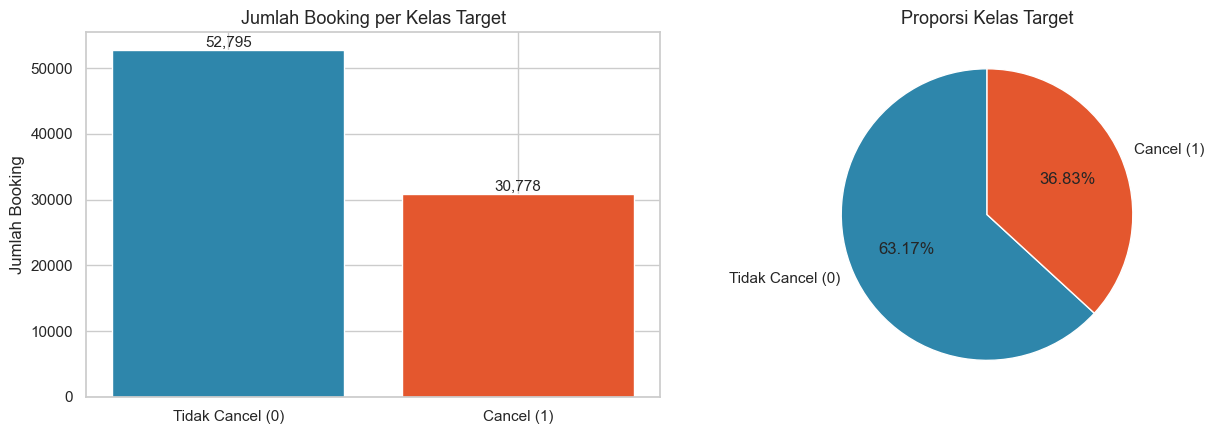

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
counts = df['is_canceled'].value_counts().sort_index()
ax[0].bar(['Tidak Cancel (0)', 'Cancel (1)'], counts.values, color=['#2E86AB', '#E4572E'])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 500, f'{v:,}', ha='center', fontsize=11)
ax[0].set_title('Jumlah Booking per Kelas Target', fontsize=13)
ax[0].set_ylabel('Jumlah Booking')
ax[1].pie(counts.values, labels=['Tidak Cancel (0)', 'Cancel (1)'], autopct='%1.2f%%', colors=['#2E86AB', '#E4572E'],
          startangle=90, wedgeprops={'edgecolor': 'white'})
ax[1].set_title('Proporsi Kelas Target', fontsize=13)
plt.tight_layout()
plt.show()

Terlihat bahwa **63,17%** booking tidak dibatalkan dan **36,83%** booking dibatalkan. Proporsi ini termasuk ***mildly imbalanced*** (tidak seimbang ringan). Angka 36,83% juga sejalan dengan data industri (D-EDGE: cancellation rate global ±40%), sehingga masalah pembatalan di hotel ini memang signifikan.

Karena kelas tidak seimbang, nanti kita akan:
- menggunakan `stratify` pada saat *train-test split* dan *Stratified K-Fold* pada *cross validation* agar proporsi kelas tetap sama di setiap bagian data,
- mencoba beberapa metode penanganan *imbalance* (*oversampling*, *undersampling*, *class weight*) dan memilih yang terbaik berdasarkan F2-Score.

## 3. Data Cleaning

Pada tahap ini kita akan memastikan data bersih dan siap digunakan, dengan memeriksa:
1. *Missing values*
2. Data duplikat
3. Nilai kategori yang tidak valid / tidak konsisten
4. *Outlier* dan anomali pada kolom numerik
5. Tipe data

Setiap keputusan akan disertai alasannya.

### 3.1 Missing Values

In [14]:
# Jumlah dan persentase missing values per kolom
missing = pd.DataFrame({'jumlah_missing': df.isna().sum(), 'persentase (%)': (df.isna().mean() * 100).round(3)})
missing[missing['jumlah_missing'] > 0]

,jumlah_missing,persentase (%)
country,351,0.42


Hanya kolom `country` yang memiliki *missing values*, yaitu **351 baris (0,42%)**. Mari kita visualisasikan dengan library `missingno`.

Reference :
- https://github.com/ResidentMario/missingno

#### Bar Plot

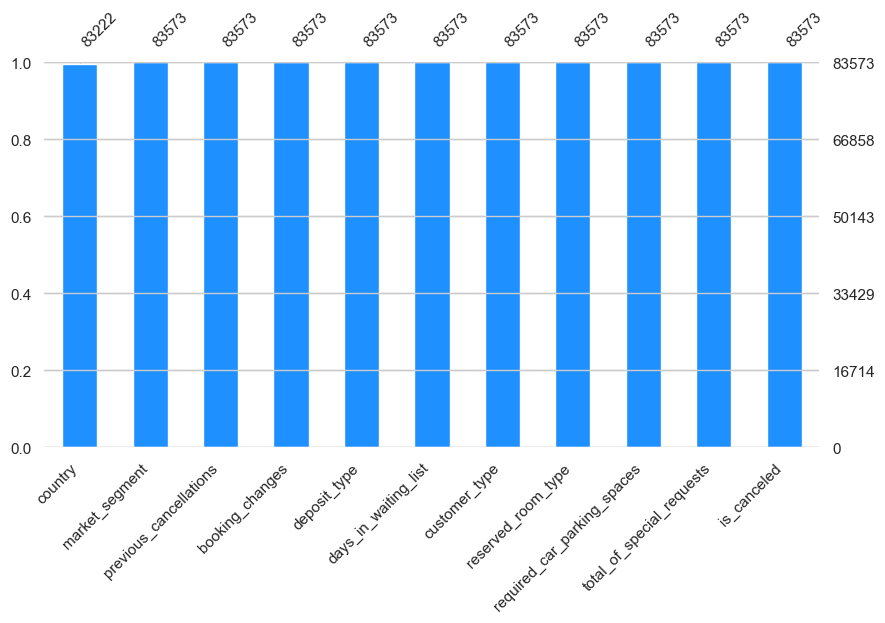

In [15]:
missingno.bar(df, color='dodgerblue', sort='ascending', figsize=(10, 5), fontsize=11)
plt.show()

Terlihat dari *bar plot* bahwa hanya kolom `country` yang tidak penuh (jumlah datanya 83.222 dari 83.573), sedangkan kolom lainnya lengkap.

#### Matrix Plot

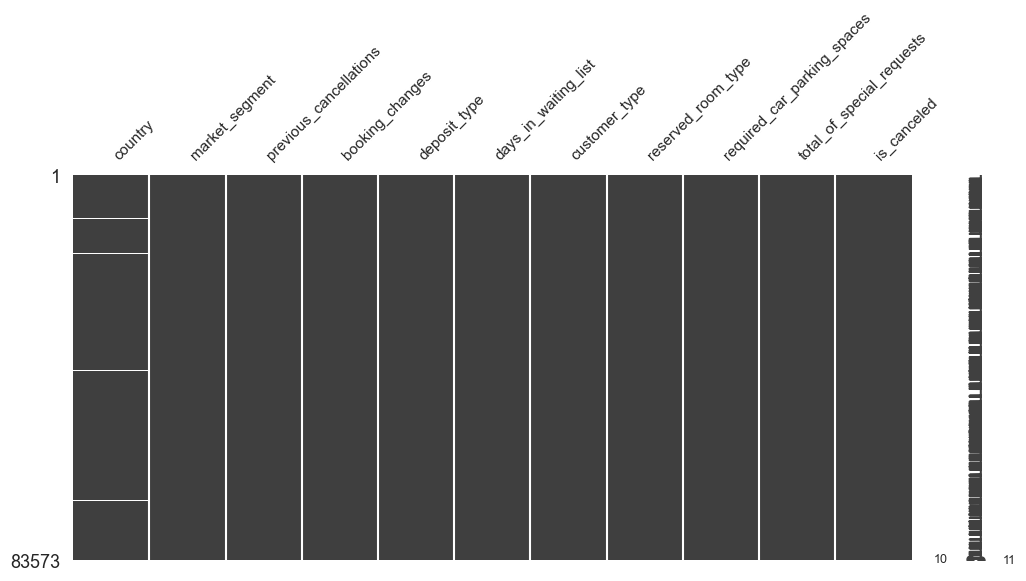

In [16]:
missingno.matrix(df, figsize=(12, 5), fontsize=11)
plt.show()

*Missing values* pada kolom `country` hanya muncul sebagai garis tipis yang tersebar dan jumlahnya sangat sedikit. Karena hanya satu kolom yang memiliki *missing values*, *heatmap* dan *dendrogram* korelasi nulitas tidak relevan untuk dataset ini (tidak ada pasangan kolom yang bisa dibandingkan).

Sekarang mari kita analisis apakah *missing values* pada `country` terjadi secara acak atau memiliki pola tertentu terhadap target.

In [17]:
# Bandingkan cancellation rate antara baris dengan country kosong dan baris dengan country terisi
pd.DataFrame({
    'jumlah_booking': [df['country'].isna().sum(), df['country'].notna().sum()],
    'cancellation_rate (%)': [round(df[df['country'].isna()]['is_canceled'].mean() * 100, 2),
                              round(df[df['country'].notna()]['is_canceled'].mean() * 100, 2)]
}, index=['country kosong (NaN)', 'country terisi'])

,jumlah_booking,cancellation_rate (%)
country kosong (NaN),351,13.11
country terisi,83222,36.93


In [18]:
# Karakteristik booking yang country-nya kosong
print('Market segment pada baris country kosong:')
display(df[df['country'].isna()]['market_segment'].value_counts())
print('Customer type pada baris country kosong:')
display(df[df['country'].isna()]['customer_type'].value_counts())

Market segment pada baris country kosong:


market_segment
Corporate        124
Direct           122
Online TA         52
Offline TA/TO     45
Complementary      5
Groups             3
Name: count, dtype: int64

Customer type pada baris country kosong:


customer_type
Transient          318
Transient-Party     29
Group                4
Name: count, dtype: int64

Terlihat bahwa booking yang `country`-nya kosong memiliki **cancellation rate hanya 13,11%**, jauh lebih rendah dibandingkan booking yang `country`-nya terisi (36,93%). Booking dengan `country` kosong juga banyak berasal dari segmen `Corporate` dan `Direct` (segmen dengan cancellation rate rendah). Artinya, ***missing values* ini tidak acak** (*Missing Not At Random*) dan justru membawa informasi.

Paper sumber data (Antonio dkk., 2019) juga menyebutkan bahwa hotel sering kali **baru mengetahui kewarganegaraan tamu secara pasti saat check-in**, sehingga data negara bisa tidak lengkap.

**Keputusan:** Kita **tidak menghapus** baris tersebut dan **tidak mengisinya dengan modus** (`PRT`), karena:
- Mengisi dengan `PRT` akan memberi informasi yang salah (cancellation rate `PRT` sangat tinggi, ±56%, sedangkan baris kosong hanya ±13%).
- Menghapus baris akan membuang informasi yang berguna.

Maka kita isi *missing values* `country` dengan kategori baru **`Unknown`**, sehingga model tetap bisa mempelajari pola "negara tidak diketahui".

In [19]:
df['country'] = df['country'].fillna('Unknown')
print('Jumlah missing values setelah diisi :', df['country'].isna().sum())
print('Jumlah booking dengan country = Unknown :', (df['country'] == 'Unknown').sum())

Jumlah missing values setelah diisi : 0
Jumlah booking dengan country = Unknown : 351


### 3.2 Data Duplikat

In [20]:
print('Jumlah baris duplikat :', df.duplicated().sum())
print('Persentase baris duplikat : {:.2f}%'.format(df.duplicated().mean() * 100))
print('Jumlah baris unik :', len(df.drop_duplicates()))

Jumlah baris duplikat : 73371
Persentase baris duplikat : 87.79%
Jumlah baris unik : 10202


Terdapat **73.371 baris duplikat (87,79%)**, hanya **10.202 baris** yang unik. Angka ini sangat besar, sehingga kita perlu berhati-hati sebelum memutuskan untuk menghapusnya. Mari kita analisis lebih dalam.

In [21]:
# Bandingkan distribusi target sebelum dan sesudah duplikat dihapus
pd.DataFrame({
    'Data asli (%)': (df['is_canceled'].value_counts(normalize=True) * 100).round(2),
    'Setelah drop duplicates (%)': (df.drop_duplicates()['is_canceled'].value_counts(normalize=True) * 100).round(2)
}).rename(index={0: '0 - Tidak Cancel', 1: '1 - Cancel'})

,Data asli (%),Setelah drop duplicates (%)
is_canceled,,
0 - Tidak Cancel,63.17,76.34
1 - Cancel,36.83,23.66


In [22]:
# Kombinasi fitur apa yang paling sering muncul berulang?
fitur = df.drop(columns=['is_canceled']).columns.tolist()
kombinasi = df.groupby(fitur)['is_canceled'].agg(['count', 'mean']).sort_values('count', ascending=False)
kombinasi.columns = ['jumlah_booking_identik', 'cancellation_rate']
kombinasi.head(10)

jumlah_booking_identik  \
country market_segment previous_cancellations booking_changes deposit_type days_in_waiting_list customer_type   reserved_room_type required_car_parking_spaces total_of_special_requests                           
PRT     Groups         0                      0               Non Refund   0                    Transient       A                  0                           0                                            4080   
        Offline TA/TO  0                      0               Non Refund   0                    Transient       A                  0                           0                                            1851   
        Groups         0                      0               No Deposit   0                    Transient-Party A                  0                           0                                            1708   
        Online TA      0                      0               No Deposit   0                    Transient       A                  0                           1                                            1554   
                                                                                                                                                               0                                            1416   
        Offline TA/TO  0                      0               No Deposit   0                    Transient-Party A                  0                           0                                            1350   
FRA     Online TA      0                      0               No Deposit   0                    Transient       A                  0                           1                                             960   
PRT     Offline TA/TO  0                      0               No Deposit   0                    Transient       A                  0                           0                                             940   
        Direct         0                      0               No Deposit   0                    Transient       A                  0                           0                                             930   
GBR     Online TA      0                      0               No Deposit   0                    Transient       A                  0                           1                                             896   

                                                                                                                                                                                          cancellation_rate  
country market_segment previous_cancellations booking_changes deposit_type days_in_waiting_list customer_type   reserved_room_type required_car_parking_spaces total_of_special_requests                     
PRT     Groups         0                      0               Non Refund   0                    Transient       A                  0                           0                                   1.000000  
        Offline TA/TO  0                      0               Non Refund   0                    Transient       A                  0                           0                                   1.000000  
        Groups         0                      0               No Deposit   0                    Transient-Party A                  0                           0                                   0.612998  
        Online TA      0                      0               No Deposit   0                    Transient       A                  0                           1                                   0.389318  
                                                                                                                                                               0                                   0.562853  
        Offline TA/TO  0                      0               No Deposit   0                    Transient-Party A                  0                           0                                   0.50

In [23]:
# Berapa banyak kombinasi fitur yang identik tetapi memiliki label target berbeda (ada yang cancel & ada yang tidak)?
konflik = kombinasi[(kombinasi['cancellation_rate'] > 0) & (kombinasi['cancellation_rate'] < 1)]
print('Jumlah kombinasi fitur unik                          :', len(kombinasi))
print('Jumlah kombinasi fitur dengan label campuran (0 & 1)  :', len(konflik))
print('Jumlah booking yang berada di kombinasi label campuran:', konflik['jumlah_booking_identik'].sum(),
      '({:.2f}% dari seluruh data)'.format(konflik['jumlah_booking_identik'].sum() / len(df) * 100))

Jumlah kombinasi fitur unik                          : 8843
Jumlah kombinasi fitur dengan label campuran (0 & 1)  : 1359
Jumlah booking yang berada di kombinasi label campuran: 50042 (59.88% dari seluruh data)


Hasil analisis duplikat:

1. **Dataset tidak memiliki ID booking** maupun informasi pembeda lain seperti tanggal booking, tanggal kedatangan, harga, atau lama menginap. Dengan hanya 10 fitur yang mayoritas kategorikal dengan sedikit nilai unik, sangat wajar jika **banyak booking yang berbeda memiliki karakteristik yang sama persis**. Contohnya, kombinasi paling umum (tamu `PRT` dari `Groups`, `Non Refund`, `Transient`, kamar `A`, tanpa permintaan khusus) muncul ribuan kali. Ini mencerminkan booking rombongan/grup yang memang terdiri dari banyak booking kamar.
2. Jika duplikat dihapus, **cancellation rate turun drastis dari 36,83% menjadi 23,66%**. Artinya penghapusan duplikat akan **mengubah distribusi data secara signifikan** dan membuat data tidak lagi merepresentasikan kondisi bisnis yang sebenarnya.
3. Banyak kombinasi fitur identik yang memiliki label campuran (sebagian cancel, sebagian tidak). Ini membuktikan bahwa baris-baris yang identik tersebut adalah **booking yang berbeda** (kalau benar-benar duplikat karena salah input, labelnya akan selalu sama).

**Keputusan:** Baris duplikat **tidak dihapus**, karena setiap baris merepresentasikan satu booking nyata dan menghapusnya akan menghilangkan informasi frekuensi yang penting bagi model (pola booking grup yang sering batal).

**Catatan penting:** Banyaknya kombinasi fitur identik dengan label campuran berarti ada batas maksimal akurasi yang bisa dicapai model mana pun dengan fitur yang tersedia. Model tidak mungkin membedakan dua booking yang fiturnya sama persis tetapi hasilnya berbeda. Hal ini akan kita bahas lagi di bagian Limitasi Model.

In [24]:
# Batas atas akurasi teoretis: jika model "menghafal" setiap kombinasi fitur dan menebak kelas mayoritasnya
max_acc = (kombinasi['jumlah_booking_identik'] * np.maximum(kombinasi['cancellation_rate'], 1 - kombinasi['cancellation_rate'])).sum() / len(df)
print('Batas atas akurasi (dengan fitur yang tersedia) : {:.2f}%'.format(max_acc * 100))

Batas atas akurasi (dengan fitur yang tersedia) : 82.65%


Bahkan model yang menghafal seluruh data latih pun **maksimal hanya bisa mencapai akurasi ±82,6%** dengan 10 fitur yang tersedia. Ini menjadi patokan realistis saat mengevaluasi model nanti, karena sisa ±17% kesalahan disebabkan oleh keterbatasan informasi pada data, bukan semata-mata kelemahan algoritma.

### 3.3 Nilai Kategori yang Tidak Valid / Tidak Konsisten

In [25]:
for col in ['market_segment', 'deposit_type', 'customer_type', 'reserved_room_type']:
    temp = df.groupby(col)['is_canceled'].agg(['count', 'mean']).rename(columns={'count': 'jumlah', 'mean': 'cancel_rate'})
    temp['cancel_rate'] = (temp['cancel_rate'] * 100).round(2)
    print(f'===== {col} =====')
    display(temp.sort_values('jumlah', ascending=False))

===== market_segment =====


,jumlah,cancel_rate
market_segment,,
Online TA,39460,36.58
Offline TA/TO,17025,34.01
Groups,13721,61.31
Direct,8898,15.14
Corporate,3792,18.09
Complementary,511,14.29
Aviation,165,21.21
Undefined,1,100.00


===== deposit_type =====


,jumlah,cancel_rate
deposit_type,,
No Deposit,73352,28.23
Non Refund,10111,99.38
Refundable,110,20.91


===== customer_type =====


,jumlah,cancel_rate
customer_type,,
Transient,62732,40.44
Transient-Party,17536,25.58
Contract,2882,30.71
Group,423,9.69


===== reserved_room_type =====


,jumlah,cancel_rate
reserved_room_type,,
A,60041,38.96
D,13526,31.56
E,4649,29.06
F,2037,29.75
G,1447,35.87
B,787,32.40
C,673,31.65
H,401,40.65
P,9,100.00


Temuan:
1. **`market_segment = Undefined`** hanya ada **1 baris**. Kategori ini tidak memiliki arti bisnis yang jelas (segmen tidak terdefinisi) dan dengan hanya 1 data, model tidak dapat mempelajari apa pun darinya. Baris ini **akan dihapus**.
2. **`reserved_room_type = P` (9 baris) dan `L` (3 baris)** jumlahnya sangat sedikit. Namun ini adalah kode tipe kamar yang valid menurut dokumentasi, jadi **tidak dihapus**. Pada tahap encoding kita menggunakan `handle_unknown='ignore'` agar model tetap aman jika kategori langka ini tidak muncul di data train.
3. Kategori lain (`deposit_type`, `customer_type`) sudah konsisten dan sesuai dokumentasi.

In [23]:
# Cek kode negara yang tidak sesuai format ISO alpha-3 (3 huruf)
print('Kode country yang panjangnya bukan 3 huruf :', [c for c in df['country'].unique() if len(c) != 3 and c != 'Unknown'])
print('Jumlah booking dengan country CN  :', (df['country'] == 'CN').sum())
print('Jumlah booking dengan country CHN :', (df['country'] == 'CHN').sum())

Kode country yang panjangnya bukan 3 huruf : ['CN']
Jumlah booking dengan country CN  : 886
Jumlah booking dengan country CHN : 709


Terdapat kode negara `CN` yang tidak sesuai format ISO alpha-3 (seharusnya 3 huruf). `CN` adalah kode ISO alpha-2 untuk China, sedangkan di data juga sudah ada `CHN` (kode alpha-3 China). Namun karena **kita tidak dapat memastikan** apakah `CN` benar-benar China (bisa juga kesalahan input untuk negara lain) dan tidak bisa mengonfirmasi ke pembuat data, `CN` **dibiarkan sebagai kategori tersendiri**. Dampaknya terhadap model kecil karena `country` akan di-*encode* dan model akan mempelajari pola masing-masing kategori.

In [26]:
# Hapus baris market_segment Undefined
print('Jumlah baris sebelum :', len(df))
df = df[df['market_segment'] != 'Undefined'].reset_index(drop=True)
print('Jumlah baris sesudah :', len(df))

Jumlah baris sebelum : 83573
Jumlah baris sesudah : 83572


### 3.4 Outlier & Anomali pada Kolom Numerik

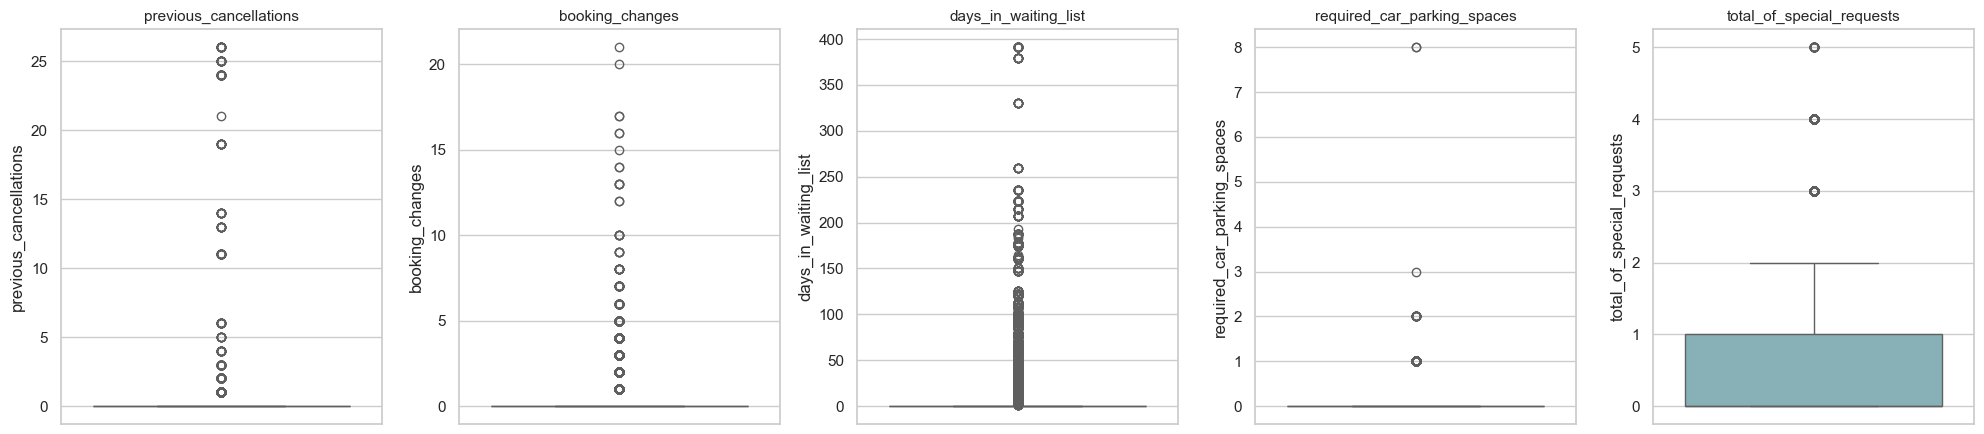

In [27]:
num_cols = ['previous_cancellations', 'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='#7FB7BE')
    ax.set_title(col, fontsize=11)
plt.tight_layout()
plt.show()

In [28]:
# Jumlah outlier berdasarkan metode IQR
listOutlier = []
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    listOutlier.append([col, Q1, Q3, IQR, lower, upper, n_out, round(n_out / len(df) * 100, 2), df[col].max()])
pd.DataFrame(listOutlier, columns=['kolom', 'Q1', 'Q3', 'IQR', 'lower_bound', 'upper_bound', 'jumlah_outlier', 'persen_outlier', 'max'])

,kolom,Q1,Q3,IQR,lower_bound,upper_bound,jumlah_outlier,persen_outlier,max
0,previous_cancellations,0.0,0.0,0.0,0.0,0.0,4513,5.40,26
1,booking_changes,0.0,0.0,0.0,0.0,0.0,12700,15.20,21
2,days_in_waiting_list,0.0,0.0,0.0,0.0,0.0,2585,3.09,391
3,required_car_parking_spaces,0.0,0.0,0.0,0.0,0.0,5227,6.25,8
4,total_of_special_requests,0.0,1.0,1.0,-1.5,2.5,2051,2.45,5


Karena Q1 dan Q3 dari hampir semua kolom numerik bernilai 0 (mayoritas booking tidak punya pembatalan sebelumnya, tidak ada perubahan, tidak masuk *waiting list*, dan tidak minta parkir), metode IQR menganggap **semua nilai > 0 sebagai outlier**. Ini tentu **tidak tepat** secara bisnis, karena nilai seperti 1 perubahan booking atau 1 tempat parkir adalah hal yang wajar.

Mari kita lihat nilai ekstrem dan hubungannya dengan target untuk menilai apakah nilai tersebut masuk akal.

In [29]:
for col in num_cols:
    temp = df.groupby(col)['is_canceled'].agg(['count', 'mean']).rename(columns={'count': 'jumlah', 'mean': 'cancel_rate'})
    temp['cancel_rate'] = (temp['cancel_rate'] * 100).round(2)
    print(f'===== {col} =====')
    display(temp.T if len(temp) <= 20 else temp.describe().T)

===== previous_cancellations =====


previous_cancellations,0,1,2,3,4,5,6,11,13,14,19,21,24,25,26
jumlah,79059.00,4207.00,86.0,46.00,19.00,7.0,19.00,28.0,10.0,10.0,12.0,1.0,33.0,17.0,18.0
cancel_rate,33.71,94.34,31.4,34.78,15.79,0.0,31.58,25.0,90.0,100.0,100.0,100.0,100.0,100.0,100.0


===== booking_changes =====


booking_changes,0,1,2,3,4,5,6,7,8,9,10,12,13,14,15,16,17,20,21
jumlah,70872.00,8963.00,2652.00,639.0,260.00,90.00,39.00,23.00,10.0,4.0,5.0,2.0,4.0,2.0,1.0,2.0,2.0,1.0,1.0
cancel_rate,40.64,14.36,19.72,14.4,16.54,15.56,30.77,4.35,40.0,0.0,20.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0


===== days_in_waiting_list =====


,count,mean,std,min,25%,50%,75%,max
jumlah,115.0,726.713043,7550.003525,1.0,4.500,15.00,33.0,80987.0
cancel_rate,115.0,55.688609,38.872438,0.0,17.425,54.55,100.0,100.0


===== required_car_parking_spaces =====


required_car_parking_spaces,0,1,2,3,8
jumlah,78345.00,5202.0,22.0,1.0,2.0
cancel_rate,39.28,0.0,0.0,0.0,0.0


===== total_of_special_requests =====


total_of_special_requests,0,1,2,3,4,5
jumlah,49188.00,23213.00,9120.00,1784.00,236.00,31.00
cancel_rate,47.51,21.99,21.57,17.21,11.86,3.23


In [30]:
# Detail nilai ekstrem
print('Booking dengan required_car_parking_spaces = 8:')
display(df[df['required_car_parking_spaces'] == 8])
print('Distribusi days_in_waiting_list (persentil):')
display(df['days_in_waiting_list'].quantile([0.5, 0.9, 0.95, 0.99, 0.999, 1.0]))

Booking dengan required_car_parking_spaces = 8:


,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled
21979,AUT,Direct,0,1,No Deposit,122,Transient-Party,E,8,0,0
35802,AUT,Direct,0,1,No Deposit,0,Transient-Party,E,8,1,0


Distribusi days_in_waiting_list (persentil):


0.500      0.00
0.900      0.00
0.950      0.00
0.990     76.29
0.999    224.00
1.000    391.00
Name: days_in_waiting_list, dtype: float64

Analisis outlier:

| Kolom | Nilai ekstrem | Masuk akal? | Keputusan |
| --- | --- | --- | --- |
| `previous_cancellations` | hingga 26 | **Ya.** Nilai tinggi umumnya milik booking dari *travel agent*/grup yang sering melakukan pemesanan (dan pembatalan) berulang. Nilai ini justru sangat informatif (cancellation rate tinggi) | Dipertahankan |
| `booking_changes` | hingga 21 | **Ya.** Booking grup/korporat bisa mengalami banyak perubahan | Dipertahankan |
| `days_in_waiting_list` | hingga 391 hari | **Ya.** Pada periode ramai, booking bisa lama berada di *waiting list*. Hanya ±3% booking yang pernah masuk *waiting list* | Dipertahankan |
| `required_car_parking_spaces` | 8 (2 baris) | **Mungkin.** Booking `Transient-Party` dari `Direct` untuk kamar tipe E (kamar besar), bisa jadi rombongan keluarga dengan beberapa mobil. Hanya 2 baris dan tidak mengganggu pola umum | Dipertahankan |
| `total_of_special_requests` | hingga 5 | **Ya.** Sesuai rentang wajar | Dipertahankan |

**Keputusan:** Tidak ada outlier yang dihapus, karena semua nilai ekstrem masih masuk akal secara bisnis dan membawa informasi penting terhadap pembatalan. Untuk mengurangi pengaruh outlier pada model berbasis jarak/linear (Logistic Regression, KNN), nanti kita menggunakan **RobustScaler** (menggunakan median dan IQR sehingga tidak sensitif terhadap outlier). Model berbasis *tree* sendiri tidak sensitif terhadap outlier karena hanya mencari titik potong (*split*).

### 3.5 Tipe Data

In [31]:
df.dtypes

country                        object
market_segment                 object
previous_cancellations          int64
booking_changes                 int64
deposit_type                   object
days_in_waiting_list            int64
customer_type                  object
reserved_room_type             object
required_car_parking_spaces     int64
total_of_special_requests       int64
is_canceled                     int64
dtype: object

Tipe data seluruh kolom sudah sesuai: kolom kategorikal bertipe *object/string* dan kolom numerik bertipe *integer*. Tidak ada kolom yang perlu dikonversi.

### 3.6 Data Setelah Cleaning

In [32]:
print('Ukuran data setelah cleaning :', df.shape)
data_desc(df)

Ukuran data setelah cleaning : (83572, 11)


,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,country,object,0,0.0,163,"[GNB, JEY]"
1,market_segment,object,0,0.0,7,"[Offline TA/TO, Online TA]"
2,previous_cancellations,int64,0,0.0,15,"[26, 4]"
3,booking_changes,int64,0,0.0,19,"[0, 4]"
4,deposit_type,object,0,0.0,3,"[No Deposit, Non Refund]"
5,days_in_waiting_list,int64,0,0.0,115,"[96, 77]"
6,customer_type,object,0,0.0,4,"[Transient, Group]"
7,reserved_room_type,object,0,0.0,10,"[L, E]"
8,required_car_parking_spaces,int64,0,0.0,5,"[1, 3]"
9,total_of_special_requests,int64,0,0.0,6,"[0, 2]"


Data sekarang sudah bersih:
- Tidak ada *missing values* (`country` kosong diisi `Unknown`).
- 1 baris `market_segment = Undefined` dihapus → **83.572 baris, 11 kolom**.
- Duplikat dipertahankan karena merepresentasikan booking yang berbeda.
- Outlier dipertahankan karena masuk akal secara bisnis.

Mari lanjut ke tahap analisis data.

## 4. Data Analysis (Exploratory Data Analysis)

Pada tahap ini kita akan mencari pola yang membedakan booking yang dibatalkan dan yang tidak dibatalkan. Untuk setiap fitur kita akan melihat **jumlah booking** dan **cancellation rate** (persentase booking yang batal) pada setiap kategori/nilainya. Sebagai pembanding, *cancellation rate* keseluruhan adalah **36,83%**.

In [33]:
overall_rate = df['is_canceled'].mean() * 100

def plot_cancel_rate(col, order=None, top_n=None, figsize=(15, 4.5), rotate=0):
    # Plot jumlah booking (stacked cancel vs tidak) dan cancellation rate per kategori
    temp = df.groupby(col)['is_canceled'].agg(['count', 'sum', 'mean'])
    temp.columns = ['jumlah', 'jumlah_cancel', 'cancel_rate']
    temp['cancel_rate'] = temp['cancel_rate'] * 100
    temp = temp.sort_values('jumlah', ascending=False)
    if top_n:
        temp = temp.head(top_n)
    if order is not None:
        temp = temp.reindex(order)
    labels = temp.index.astype(str)

    fig, ax = plt.subplots(1, 2, figsize=figsize)
    ax[0].bar(labels, temp['jumlah'] - temp['jumlah_cancel'], color='#2E86AB', label='Tidak Cancel')
    ax[0].bar(labels, temp['jumlah_cancel'], bottom=temp['jumlah'] - temp['jumlah_cancel'], color='#E4572E', label='Cancel')
    ax[0].set_title(f'Jumlah Booking per {col}', fontsize=12)
    ax[0].legend()
    ax[0].tick_params(axis='x', rotation=rotate)

    colors = ['#E4572E' if r > overall_rate else '#9DB4C0' for r in temp['cancel_rate']]
    ax[1].bar(labels, temp['cancel_rate'], color=colors)
    ax[1].axhline(overall_rate, color='black', linestyle='--', linewidth=1, label=f'Overall {overall_rate:.2f}%')
    for i, v in enumerate(temp['cancel_rate']):
        ax[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
    ax[1].set_title(f'Cancellation Rate per {col}', fontsize=12)
    ax[1].set_ylabel('Cancellation Rate (%)')
    ax[1].set_ylim(0, 110)
    ax[1].legend()
    ax[1].tick_params(axis='x', rotation=rotate)
    plt.tight_layout()
    plt.show()
    return temp.round(2)

### 4.1 Deposit Type

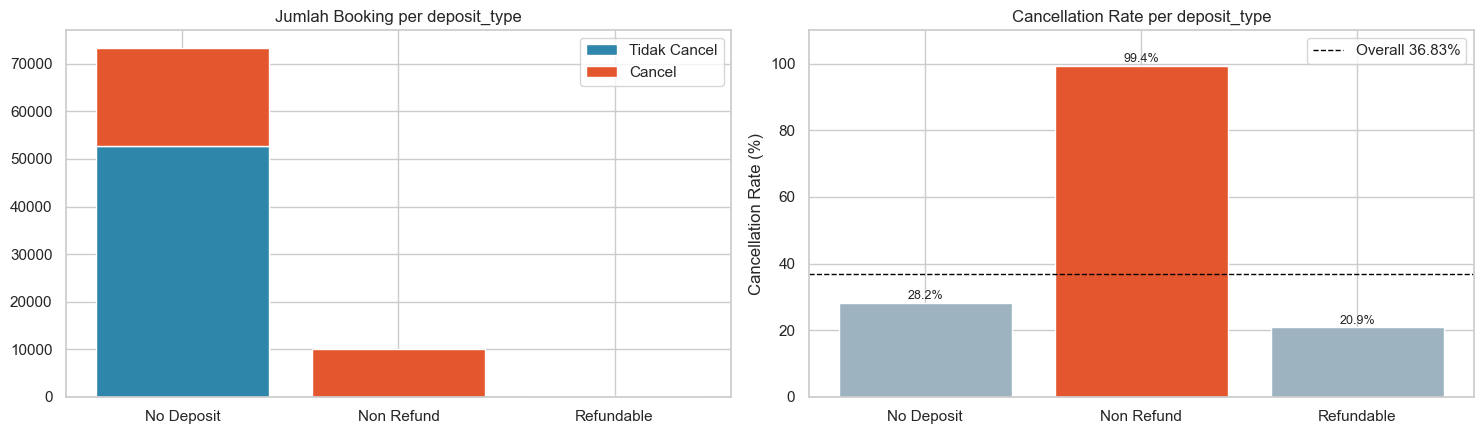

,jumlah,jumlah_cancel,cancel_rate
deposit_type,,,
No Deposit,73351,20706,28.23
Non Refund,10111,10048,99.38
Refundable,110,23,20.91


In [34]:
plot_cancel_rate('deposit_type')

In [35]:
# Booking Non Refund berasal dari segmen dan negara apa?
print('Market segment pada booking Non Refund:')
display(df[df['deposit_type'] == 'Non Refund']['market_segment'].value_counts())
print('Top 5 country pada booking Non Refund:')
display(df[df['deposit_type'] == 'Non Refund']['country'].value_counts().head())

Market segment pada booking Non Refund:


market_segment
Groups           6371
Offline TA/TO    3463
Corporate         229
Online TA          36
Direct             12
Name: count, dtype: int64

Top 5 country pada booking Non Refund:


country
PRT    9837
GBR      97
ESP      79
DEU      28
POL      27
Name: count, dtype: int64

**Insight `deposit_type`:**
- Booking dengan deposit **`Non Refund` memiliki cancellation rate 99,4%**, sangat jauh di atas rata-rata. Sebaliknya `No Deposit` hanya 28,2% dan `Refundable` 20,9%.
- Secara logika, booking *non-refundable* seharusnya **jarang** dibatalkan karena uang tamu tidak kembali. Pola yang terbalik ini disebabkan karena booking `Non Refund` di data ini **didominasi segmen `Groups` dan `Offline TA/TO`, serta hampir semuanya berasal dari `PRT`**. Kemungkinan besar ini adalah blok kamar (*allotment*) dari *tour operator*/agen lokal yang dicatat sebagai `Non Refund` lalu dibatalkan/dilepas dalam jumlah besar.
- Ini adalah pola yang sangat kuat bagi model, tetapi **perlu dikonfirmasi ke pihak hotel** apakah deposit benar-benar dibayar. Jika ya, kerugian dari pembatalan `Non Refund` sebenarnya lebih kecil (deposit tetap diterima hotel). Hal ini kita catat sebagai limitasi.

### 4.2 Market Segment

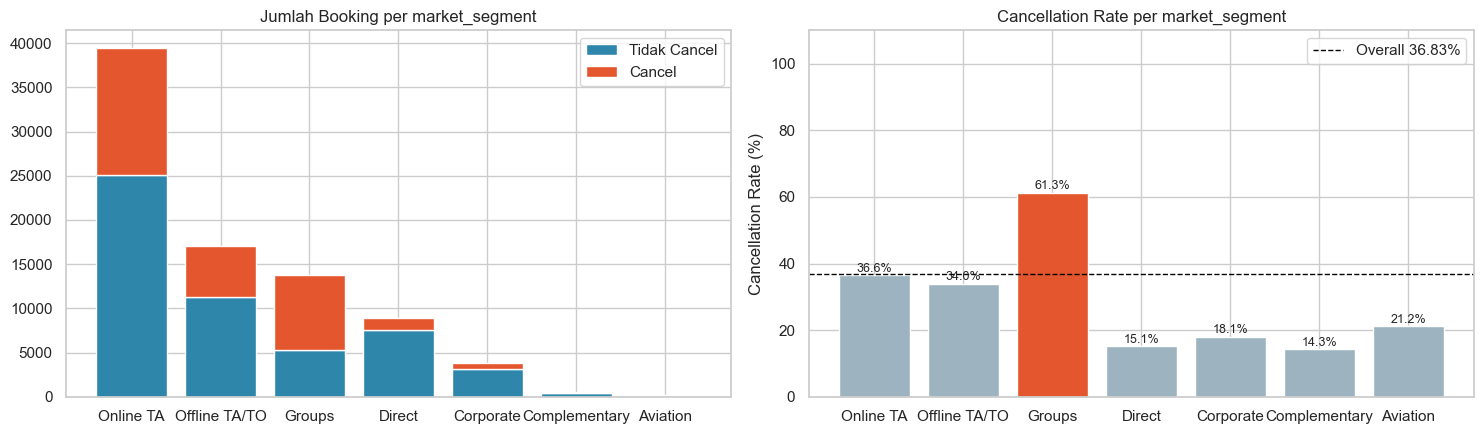

,jumlah,jumlah_cancel,cancel_rate
market_segment,,,
Online TA,39460,14433,36.58
Offline TA/TO,17025,5791,34.01
Groups,13721,8412,61.31
Direct,8898,1347,15.14
Corporate,3792,686,18.09
Complementary,511,73,14.29
Aviation,165,35,21.21


In [36]:
plot_cancel_rate('market_segment')

**Insight `market_segment`:**
- Segmen **`Groups` memiliki cancellation rate tertinggi (61,3%)**, diikuti `Online TA` (36,6%) dan `Offline TA/TO` (34,0%).
- `Online TA` adalah segmen dengan **jumlah booking terbanyak** (±47% dari semua booking) dan cancellation rate yang hampir sama dengan rata-rata, sehingga secara absolut menyumbang jumlah pembatalan yang sangat besar. Ini sejalan dengan temuan D-EDGE bahwa channel OTA (seperti Booking.com) cenderung memiliki cancellation rate tinggi karena kebijakan *free cancellation*.
- Segmen **`Direct` (15,1%), `Corporate` (18,1%), `Complementary` (14,3%) dan `Aviation` (21,2%) jauh lebih rendah**. Tamu yang memesan langsung ke hotel atau melalui perusahaan cenderung lebih berkomitmen.

### 4.3 Customer Type

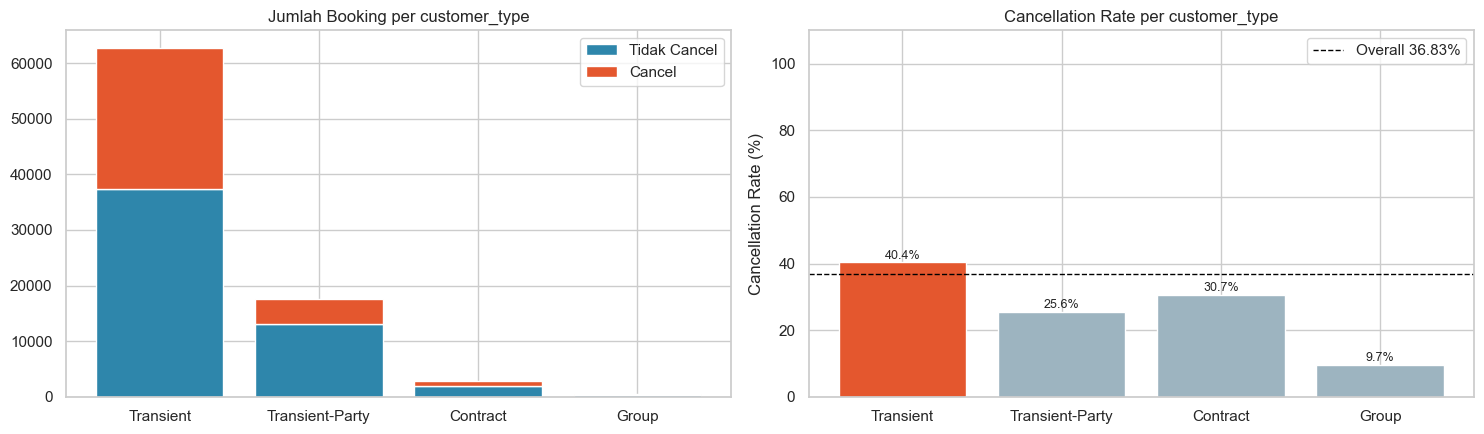

,jumlah,jumlah_cancel,cancel_rate
customer_type,,,
Transient,62732,25366,40.44
Transient-Party,17535,4485,25.58
Contract,2882,885,30.71
Group,423,41,9.69


In [37]:
plot_cancel_rate('customer_type')

**Insight `customer_type`:**
- Tipe **`Transient` (tamu individu) memiliki cancellation rate tertinggi (40,4%)** dan merupakan mayoritas booking (±75%).
- `Group` justru paling rendah (9,7%) dan `Transient-Party` 25,6%. Perlu diperhatikan bahwa `customer_type = Group` berbeda dengan `market_segment = Groups`: `customer_type` menunjukkan tipe booking-nya, sedangkan `market_segment` menunjukkan sumber/segmen pasarnya.

### 4.4 Reserved Room Type

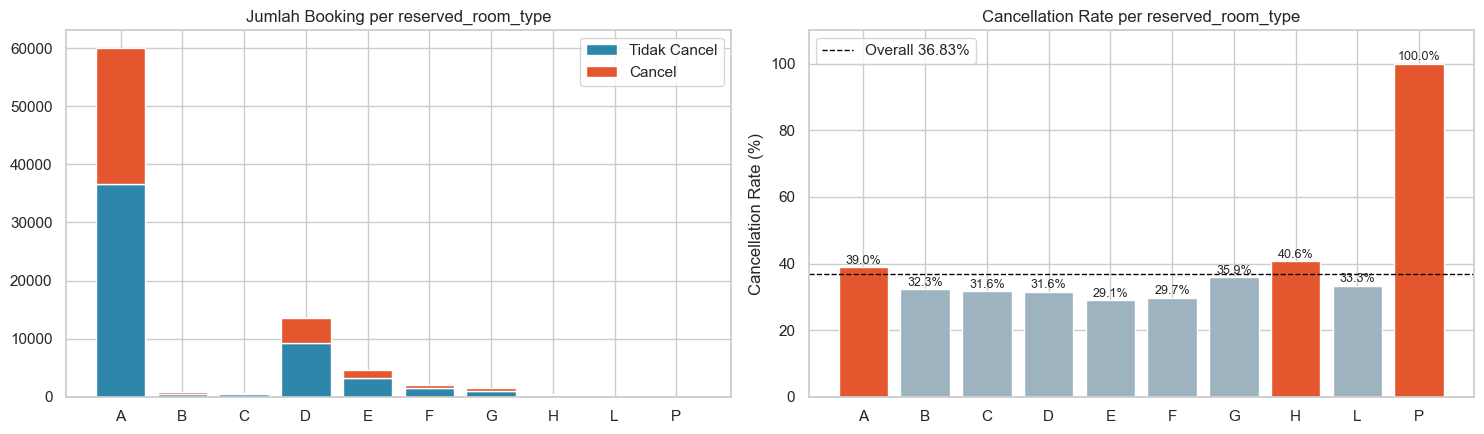

,jumlah,jumlah_cancel,cancel_rate
reserved_room_type,,,
A,60041,23392,38.96
B,786,254,32.32
C,673,213,31.65
D,13526,4269,31.56
E,4649,1351,29.06
F,2037,606,29.75
G,1447,519,35.87
H,401,163,40.65
L,3,1,33.33


In [38]:
plot_cancel_rate('reserved_room_type', order=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L', 'P'])

**Insight `reserved_room_type`:**
- Tipe kamar **A** mendominasi (±72% booking) dengan cancellation rate 39,0%, sedikit di atas rata-rata.
- Tipe kamar lain (B–H) berada di kisaran 29%–41%, relatif tidak jauh berbeda. Perbedaan tipe kamar tidak sekuat fitur lain dalam membedakan pembatalan.
- Tipe `P` (9 booking, semua cancel) dan `L` (3 booking) jumlahnya terlalu sedikit untuk disimpulkan.

### 4.5 Country

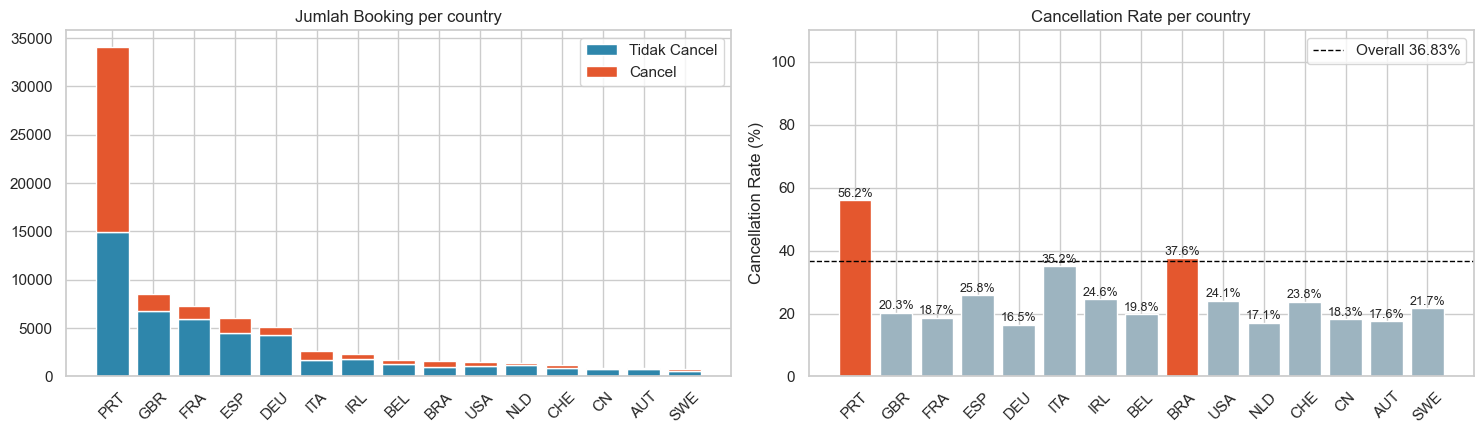

,jumlah,jumlah_cancel,cancel_rate
country,,,
PRT,34096,19156,56.18
GBR,8495,1724,20.29
FRA,7307,1366,18.69
ESP,5996,1546,25.78
DEU,5116,844,16.50
ITA,2658,935,35.18
IRL,2340,576,24.62
BEL,1648,326,19.78
BRA,1553,584,37.60


In [39]:
country_tab = plot_cancel_rate('country', top_n=15, rotate=45)
country_tab

In [40]:
# Perbandingan tamu domestik (Portugal) vs internasional
dom = df.assign(asal=np.where(df['country'] == 'PRT', 'Domestik (PRT)', 'Internasional / Unknown'))
temp = dom.groupby('asal')['is_canceled'].agg(['count', 'mean'])
temp.columns = ['jumlah', 'cancel_rate (%)']
temp['cancel_rate (%)'] = (temp['cancel_rate (%)'] * 100).round(2)
temp['porsi_booking (%)'] = (temp['jumlah'] / len(df) * 100).round(2)
temp

,jumlah,cancel_rate (%),porsi_booking (%)
asal,,,
Domestik (PRT),34096,56.18,40.8
Internasional / Unknown,49476,23.49,59.2


**Insight `country`:**
- Tamu dari **Portugal (`PRT`) mendominasi** (±41% booking) dan memiliki **cancellation rate sangat tinggi (56,2%)**, sekitar **2,4 kali lipat** dibanding rata-rata tamu internasional/unknown (23,5%). Negara-negara asal tamu internasional terbanyak umumnya hanya 16%–26% (misalnya `GBR` 20,3%, `FRA` 18,7%, `DEU` 16,5%), dengan beberapa pengecualian seperti `ITA` (35,2%) dan `BRA` (37,6%).
- Tamu domestik lebih mudah membatalkan karena jarak dekat dan biaya perjalanan rendah, sedangkan tamu internasional biasanya sudah memesan tiket pesawat sehingga lebih berkomitmen. Selain itu, sebagian besar booking `Non Refund` grup juga berasal dari `PRT`.
- **Catatan:** Antonio dkk. (2019) menyebutkan hotel sering baru mengetahui kewarganegaraan pasti saat *check-in*. Jadi ada kemungkinan booking yang batal (tamu tidak pernah *check-in*) tetap tercatat dengan negara *default* tertentu. Hal ini perlu diwaspadai sebagai potensi *data leakage* dan akan diuji di bagian Limitasi Model.

### 4.6 Fitur Numerik

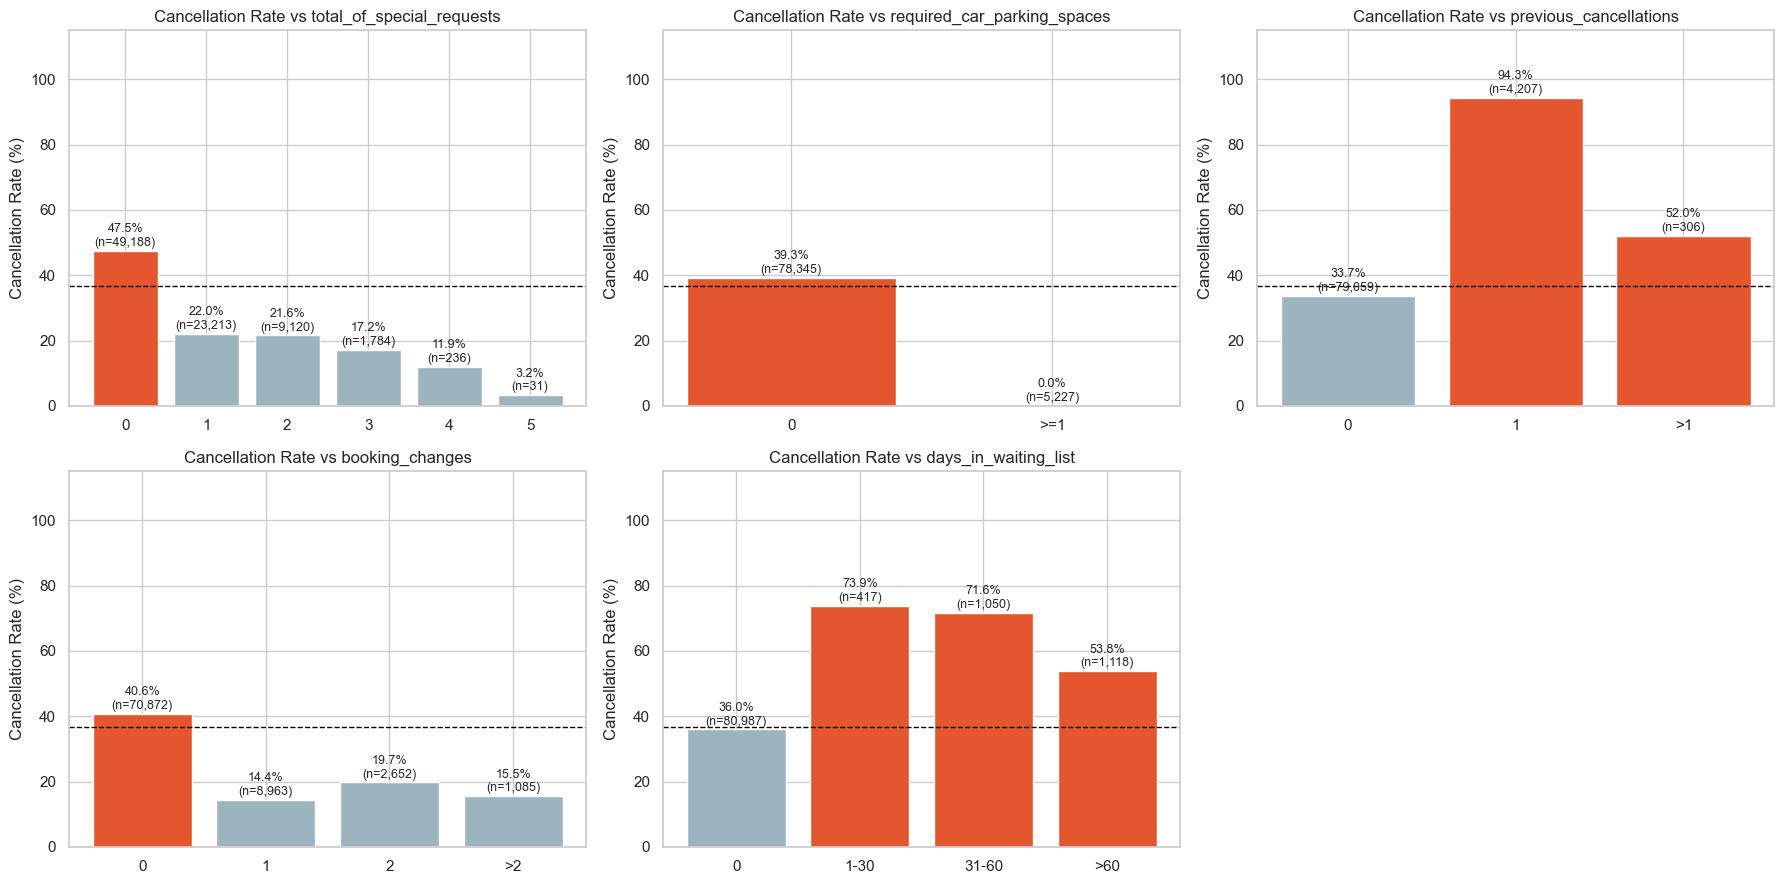

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
plot_specs = [
    ('total_of_special_requests', df['total_of_special_requests'].astype(str), None),
    ('required_car_parking_spaces', df['required_car_parking_spaces'].clip(upper=1).map({0: '0', 1: '>=1'}), None),
    ('previous_cancellations', pd.cut(df['previous_cancellations'], [-1, 0, 1, 100], labels=['0', '1', '>1']), None),
    ('booking_changes', pd.cut(df['booking_changes'], [-1, 0, 1, 2, 100], labels=['0', '1', '2', '>2']), None),
    ('days_in_waiting_list', pd.cut(df['days_in_waiting_list'], [-1, 0, 30, 60, 1000], labels=['0', '1-30', '31-60', '>60']), None),
]
for ax, (name, grouped, _) in zip(axes.flatten(), plot_specs):
    temp = df.groupby(grouped)['is_canceled'].agg(['mean', 'count'])
    temp = temp.sort_index()
    bars = ax.bar(temp.index.astype(str), temp['mean'] * 100, color=['#E4572E' if v * 100 > overall_rate else '#9DB4C0' for v in temp['mean']])
    ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1)
    for i, (v, n) in enumerate(zip(temp['mean'] * 100, temp['count'])):
        ax.text(i, v + 1.5, f'{v:.1f}%\n(n={n:,})', ha='center', fontsize=9)
    ax.set_title(f'Cancellation Rate vs {name}', fontsize=12)
    ax.set_ylabel('Cancellation Rate (%)')
    ax.set_ylim(0, 115)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

**Insight fitur numerik** (garis putus-putus = rata-rata 36,83%):
1. **`total_of_special_requests`**: semakin banyak permintaan khusus, semakin kecil kemungkinan batal. Booking tanpa permintaan khusus memiliki cancellation rate **47,5%**, sedangkan 1 permintaan turun menjadi 22,0% dan 5 permintaan hanya 3,2%. Tamu yang meminta sesuatu yang spesifik (misalnya *twin bed*, lantai tinggi) menunjukkan **niat menginap yang lebih serius**.
2. **`required_car_parking_spaces`**: booking yang meminta parkir **tidak ada satu pun yang batal (0%)**, sedangkan yang tidak meminta parkir 39,3%. Pola "sempurna" seperti ini mencurigakan: bisa jadi permintaan parkir baru dicatat saat tamu sudah datang (*check-in*), sehingga berpotensi menjadi *data leakage*. Akan diuji di bagian Limitasi Model.
3. **`previous_cancellations`**: tamu yang pernah membatalkan **1 kali** sebelumnya memiliki cancellation rate **94,3%**, sedangkan > 1 kali 52,0% dan belum pernah 33,7%. Riwayat pembatalan adalah indikator kuat perilaku tamu.
4. **`booking_changes`**: booking **tanpa perubahan** memiliki cancellation rate 40,6%, sedangkan booking yang pernah diubah jauh lebih rendah (±14%–20%). Tamu yang mengubah booking (misalnya tanggal/tipe kamar) cenderung tetap berencana datang.
5. **`days_in_waiting_list`**: booking yang pernah masuk *waiting list* memiliki cancellation rate **64,3%** (vs 36,0% yang langsung terkonfirmasi). Cancellation rate tertinggi ada pada kelompok 1–30 hari (73,9%) dan 31–60 hari (71,6%), lalu turun pada > 60 hari (53,8%). Jadi yang penting adalah **pernah atau tidaknya** masuk *waiting list*, bukan semakin lama semakin tinggi. Selama menunggu konfirmasi, tamu kemungkinan sudah memesan alternatif di hotel lain.

### 4.7 Uji Statistik: Chi-Square Test & Cramér's V

Untuk memastikan setiap fitur memiliki hubungan yang signifikan dengan target (bukan kebetulan), kita lakukan **Chi-Square Test of Independence** antara setiap fitur dan `is_canceled`:
- **H0**: fitur dan target saling independen (tidak berhubungan).
- **H1**: fitur dan target tidak independen (berhubungan).
- Jika *p-value* < 0,05 → tolak H0 → fitur berhubungan signifikan dengan target.

Karena *p-value* pada data besar hampir selalu sangat kecil, kita juga menghitung **Cramér's V** untuk mengukur **kekuatan** hubungan (0 = tidak ada hubungan, 1 = hubungan sempurna). Interpretasi umum: < 0,1 lemah; 0,1–0,3 sedang; > 0,3 kuat. Fitur numerik di sini bersifat diskrit, sehingga juga dapat diuji dengan Chi-Square.

In [42]:
def cramers_v(confusion):
    chi2 = chi2_contingency(confusion)[0]
    n = confusion.values.sum()
    r, k = confusion.shape
    return np.sqrt((chi2 / n) / (min(k - 1, r - 1)))

hasil_uji = []
for col in df.drop(columns=['is_canceled']).columns:
    tab = pd.crosstab(df[col], df['is_canceled'])
    chi2, p, dof, _ = chi2_contingency(tab)
    hasil_uji.append([col, round(chi2, 2), p, 'Signifikan' if p < 0.05 else 'Tidak Signifikan', round(cramers_v(tab), 4)])
hasil_uji = pd.DataFrame(hasil_uji, columns=['fitur', 'chi2', 'p_value', 'kesimpulan', 'cramers_v']).sort_values('cramers_v', ascending=False).reset_index(drop=True)
hasil_uji

,fitur,chi2,p_value,kesimpulan,cramers_v
0,deposit_type,19346.92,0.000000e+00,Signifikan,0.4811
1,country,10772.44,0.000000e+00,Signifikan,0.3590
2,previous_cancellations,6491.71,0.000000e+00,Signifikan,0.2787
3,market_segment,6093.67,0.000000e+00,Signifikan,0.2700
4,total_of_special_requests,5894.78,0.000000e+00,Signifikan,0.2656
5,required_car_parking_spaces,3250.39,0.000000e+00,Signifikan,0.1972
6,booking_changes,2943.64,0.000000e+00,Signifikan,0.1877
7,days_in_waiting_list,2256.89,0.000000e+00,Signifikan,0.1643
8,customer_type,1485.22,0.000000e+00,Signifikan,0.1333
9,reserved_room_type,476.20,7.131516e-97,Signifikan,0.0755


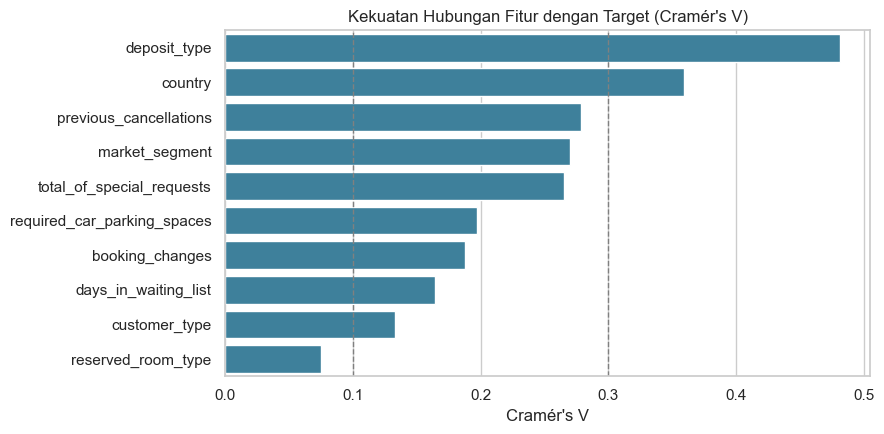

In [43]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=hasil_uji, y='fitur', x='cramers_v', color='#2E86AB')
plt.axvline(0.1, color='grey', linestyle='--', linewidth=1)
plt.axvline(0.3, color='grey', linestyle='--', linewidth=1)
plt.title("Kekuatan Hubungan Fitur dengan Target (Cramér's V)", fontsize=12)
plt.xlabel("Cramér's V")
plt.ylabel('')
plt.tight_layout()
plt.show()

**Hasil uji statistik:**
- **Semua fitur memiliki *p-value* < 0,05**, artinya semua fitur berhubungan signifikan dengan pembatalan.
- Fitur dengan hubungan **paling kuat** (Cramér's V > 0,3) adalah `deposit_type` (0,48) dan `country` (0,36).
- Fitur dengan hubungan **sedang** (0,1–0,3) adalah `previous_cancellations`, `market_segment`, `total_of_special_requests`, `required_car_parking_spaces`, `booking_changes`, `days_in_waiting_list`, dan `customer_type`.
- `reserved_room_type` memiliki hubungan paling lemah (0,08 < 0,1), sesuai dengan hasil visualisasi bahwa cancellation rate antar tipe kamar tidak jauh berbeda.

### 4.8 Ringkasan Insight EDA

1. **Deposit `Non Refund`** (99,4% batal), **riwayat 1 kali pembatalan** (94,3%), **segmen `Groups`** (61,3%), **masuk *waiting list*** (64,3%), dan **tamu domestik `PRT`** (56,2%) adalah karakteristik booking dengan risiko pembatalan **sangat tinggi**.
2. **Permintaan khusus**, **permintaan parkir**, **perubahan booking**, serta segmen **`Direct`/`Corporate`** adalah karakteristik booking yang **lebih berkomitmen** (risiko rendah).
3. `reserved_room_type` memiliki pengaruh paling lemah.
4. Beberapa pola sangat ekstrem (`Non Refund` 99,4%, parkir 0%, `PRT` 56%) perlu dikonfirmasi ke hotel mengenai **kapan data tersebut dicatat** untuk memastikan tidak ada *data leakage*.

Mari sekarang kita siapkan data untuk pemodelan.

## 5. Data Preparation & Feature Engineering

### 5.1 Feature Selection

Berdasarkan pemahaman bisnis dan hasil uji statistik, **seluruh 10 fitur digunakan** untuk pemodelan:

| Fitur | Digunakan? | Alasan |
| --- | --- | --- |
| `country` | Ya | Hubungan kuat dengan target (Cramér's V tertinggi kedua). Informasi asal tamu tersedia saat booking (meskipun dapat dikoreksi saat check-in → diuji pada bagian limitasi) |
| `market_segment` | Ya | Signifikan; menggambarkan sumber booking yang memiliki perilaku pembatalan berbeda |
| `previous_cancellations` | Ya | Hubungan sedang; riwayat perilaku tamu |
| `booking_changes` | Ya | Signifikan; menunjukkan keterlibatan tamu terhadap booking-nya |
| `deposit_type` | Ya | Hubungan kuat; kebijakan pembayaran |
| `days_in_waiting_list` | Ya | Signifikan; waktu tunggu konfirmasi |
| `customer_type` | Ya | Signifikan; tipe booking |
| `reserved_room_type` | Ya | Signifikan walaupun lemah; tetap dipertahankan karena jumlah kategorinya sedikit sehingga tidak membebani model, dan model *tree* dapat memanfaatkannya bila berinteraksi dengan fitur lain |
| `required_car_parking_spaces` | Ya | Hubungan sedang (perlu diwaspadai potensi *leakage* → diuji di bagian limitasi) |
| `total_of_special_requests` | Ya | Hubungan sedang; menunjukkan keseriusan tamu |

Tidak ada fitur yang berupa ID atau informasi yang jelas-jelas baru diketahui setelah status pembatalan terjadi, sehingga tidak ada fitur yang dihapus.

### 5.2 Rencana Encoding & Scaling

Model *machine learning* hanya dapat menerima input numerik, sehingga fitur kategorikal harus di-*encode*:

| Fitur | Metode | Alasan |
| --- | --- | --- |
| `market_segment` (7 kategori) | **One Hot Encoding** | Nominal (tidak memiliki urutan), jumlah kategori sedikit |
| `deposit_type` (3 kategori) | **One Hot Encoding** | Nominal, jumlah kategori sedikit |
| `customer_type` (4 kategori) | **One Hot Encoding** | Nominal, jumlah kategori sedikit |
| `reserved_room_type` (10 kategori) | **One Hot Encoding** | Kode kamar bersifat nominal (huruf A–P tidak menunjukkan urutan kelas kamar yang pasti karena dianonimkan), jumlah kategori masih sedikit |
| `country` (162 kategori + Unknown) | **Binary Encoding** | Nominal dengan kardinalitas tinggi. One Hot Encoding akan menghasilkan ±162 kolom baru yang sangat *sparse*, sedangkan Ordinal/Label Encoding akan memberikan urutan palsu. Binary Encoding hanya menghasilkan ±8 kolom (2^8 = 256 ≥ 163 kategori) |
| 5 fitur numerik | **RobustScaler** | Distribusi sangat *skewed* dan memiliki outlier. RobustScaler menggunakan median & IQR sehingga tidak terpengaruh outlier. Scaling penting untuk Logistic Regression dan KNN (berbasis jarak/bobot); tidak berpengaruh negatif pada model *tree* |

Catatan:
- One Hot Encoding menggunakan `drop='first'` untuk menghindari *dummy variable trap* (multikolinearitas sempurna pada model linear), dan `handle_unknown='ignore'` agar pipeline tidak error jika muncul kategori baru di data produksi.
- Semua *encoding* dan *scaling* dimasukkan ke dalam **Pipeline** sehingga hanya di-*fit* pada data train (mencegah *data leakage* dari data test/validation).
- Pilihan Binary Encoding untuk `country` akan kita **validasi dengan eksperimen** di bagian 5.4.

### 5.3 Train-Test Split

Data dibagi menjadi **80% data train** dan **20% data test** menggunakan `stratify=y` agar proporsi kelas cancel/tidak cancel sama di kedua bagian. Data test **hanya digunakan di akhir** untuk mengevaluasi model final, sedangkan pemilihan model, eksperimen *feature engineering*, dan *hyperparameter tuning* dilakukan dengan **Stratified K-Fold Cross Validation pada data train**.

In [44]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=RANDOM_STATE)

print('Ukuran X_train :', X_train.shape, '| Ukuran X_test :', X_test.shape)
pd.DataFrame({'train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
              'test (%)': (y_test.value_counts(normalize=True) * 100).round(2)})

Ukuran X_train : (66857, 10) | Ukuran X_test : (16715, 10)


,train (%),test (%)
is_canceled,,
0,63.17,63.17
1,36.83,36.83


Proporsi kelas pada data train dan test sudah sama (±63% : 37%).

In [45]:
cat_ohe = ['market_segment', 'deposit_type', 'customer_type', 'reserved_room_type']
cat_binary = ['country']
num_cols = ['previous_cancellations', 'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']

transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_ohe),
    ('binary', ce.BinaryEncoder(), cat_binary),
    ('robust', RobustScaler(), num_cols)
], remainder='drop')
transformer

,transformers,"[('onehot', ...), ('binary', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,'first'
,sparse_output,True


In [46]:
# Contoh hasil transformasi pada data train
X_train_transformed = pd.DataFrame(transformer.fit_transform(X_train), columns=transformer.get_feature_names_out())
print('Jumlah fitur setelah transformasi :', X_train_transformed.shape[1])
X_train_transformed.head()

Jumlah fitur setelah transformasi : 33


,onehot__market_segment_Complementary,onehot__market_segment_Corporate,onehot__market_segment_Direct,onehot__market_segment_Groups,onehot__market_segment_Offline TA/TO,onehot__market_segment_Online TA,onehot__deposit_type_Non Refund,onehot__deposit_type_Refundable,onehot__customer_type_Group,onehot__customer_type_Transient,onehot__customer_type_Transient-Party,onehot__reserved_room_type_B,onehot__reserved_room_type_C,onehot__reserved_room_type_D,onehot__reserved_room_type_E,onehot__reserved_room_type_F,onehot__reserved_room_type_G,onehot__reserved_room_type_H,onehot__reserved_room_type_L,onehot__reserved_room_type_P,binary__country_0,binary__country_1,binary__country_2,binary__country_3,binary__country_4,binary__country_5,binary__country_6,binary__country_7,robust__previous_cancellations,robust__booking_changes,robust__days_in_waiting_list,robust__required_car_parking_spaces,robust__total_of_special_requests
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


Setelah transformasi, 10 fitur awal berubah menjadi beberapa puluh fitur numerik: kolom `onehot__*` hasil One Hot Encoding, kolom `binary__country_*` hasil Binary Encoding, dan kolom `robust__*` hasil RobustScaler.

In [47]:
# Definisi skema evaluasi yang dipakai di seluruh eksperimen
f2_scorer = make_scorer(fbeta_score, beta=2)
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'f2': f2_scorer, 'recall': 'recall', 'precision': 'precision', 'roc_auc': 'roc_auc'}

### 5.4 Eksperimen Feature Engineering 1: Metode Encoding untuk `country`

Kita bandingkan 3 metode encoding untuk `country` menggunakan model referensi **XGBoost (default)** dan 5-Fold Cross Validation pada data train:
1. **Binary Encoding** (rencana awal).
2. **One Hot Encoding + pengelompokan kategori langka** (`min_frequency=100`: negara dengan < 100 booking digabung menjadi satu kategori *infrequent*).
3. **Target Encoding** (mengganti kategori dengan rata-rata target, dihitung hanya dari fold train).

In [48]:
encoders_country = {
    'Binary Encoding': ce.BinaryEncoder(),
    'One Hot (min_frequency=100)': OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=100),
    'Target Encoding': ce.TargetEncoder()
}
hasil_enc = []
for nama, enc in encoders_country.items():
    trans = ColumnTransformer([
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_ohe),
        ('country', enc, cat_binary),
        ('robust', RobustScaler(), num_cols)])
    pipe = Pipeline([('preprocess', trans), ('model', XGBClassifier(random_state=RANDOM_STATE, verbosity=0))])
    cv = cross_validate(pipe, X_train, y_train, cv=skfold, scoring=scoring)
    n_feat = trans.fit_transform(X_train, y_train).shape[1]
    hasil_enc.append([nama, n_feat, cv['test_f2'].mean(), cv['test_f2'].std(), cv['test_roc_auc'].mean()])
pd.DataFrame(hasil_enc, columns=['encoding country', 'jumlah fitur', 'mean F2', 'std F2', 'mean ROC-AUC']).round(4)

,encoding country,jumlah fitur,mean F2,std F2,mean ROC-AUC
0,Binary Encoding,33,0.7065,0.0029,0.8942
1,One Hot (min_frequency=100),58,0.7034,0.0121,0.8950
2,Target Encoding,26,0.7100,0.0087,0.8952


Hasilnya, ketiga metode encoding menghasilkan F2-Score dan ROC-AUC yang **hampir sama** (selisih < 0,01, masih dalam rentang standar deviasi). Maka kita tetap menggunakan **Binary Encoding**, karena:
- Jumlah fitur yang dihasilkan **lebih sedikit** dibanding One Hot Encoding (lebih efisien).
- **Tidak menggunakan informasi target** seperti Target Encoding, sehingga risiko *overfitting/target leakage* lebih kecil, terutama untuk negara dengan jumlah booking sangat sedikit.

### 5.5 Eksperimen Feature Engineering 2: Penambahan Fitur Baru

Berdasarkan insight EDA, kita mencoba membuat beberapa fitur *flag* baru yang secara bisnis masuk akal:
- `is_domestic` = 1 jika `country == 'PRT'` (tamu domestik memiliki cancellation rate jauh lebih tinggi).
- `has_prev_cancel` = 1 jika `previous_cancellations > 0`.
- `in_waiting_list` = 1 jika `days_in_waiting_list > 0`.
- `has_special_request` = 1 jika `total_of_special_requests > 0`.

Kita bandingkan performa model referensi (XGBoost + RandomOverSampler) dengan dan tanpa fitur tambahan ini.

In [49]:
def add_new_features(data):
    data = data.copy()
    data['is_domestic'] = (data['country'] == 'PRT').astype(int)
    data['has_prev_cancel'] = (data['previous_cancellations'] > 0).astype(int)
    data['in_waiting_list'] = (data['days_in_waiting_list'] > 0).astype(int)
    data['has_special_request'] = (data['total_of_special_requests'] > 0).astype(int)
    return data

new_feats = ['is_domestic', 'has_prev_cancel', 'in_waiting_list', 'has_special_request']
trans_fe = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_ohe),
    ('binary', ce.BinaryEncoder(), cat_binary),
    ('robust', RobustScaler(), num_cols + new_feats)])

hasil_fe = []
for nama, trans, data in [('Tanpa fitur baru', transformer, X_train), ('Dengan fitur baru', trans_fe, add_new_features(X_train))]:
    pipe = Pipeline([('preprocess', trans), ('resampling', RandomOverSampler(random_state=RANDOM_STATE)),
                     ('model', XGBClassifier(random_state=RANDOM_STATE, verbosity=0))])
    cv = cross_validate(pipe, data, y_train, cv=skfold, scoring=scoring)
    hasil_fe.append([nama, cv['test_f2'].mean(), cv['test_f2'].std(), cv['test_roc_auc'].mean()])
pd.DataFrame(hasil_fe, columns=['skenario', 'mean F2', 'std F2', 'mean ROC-AUC']).round(4)

,skenario,mean F2,std F2,mean ROC-AUC
0,Tanpa fitur baru,0.7722,0.0044,0.8938
1,Dengan fitur baru,0.7756,0.0064,0.8945


Penambahan fitur baru **tidak memberikan peningkatan yang berarti** (selisih F2 lebih kecil dari standar deviasinya). Hal ini masuk akal karena model berbasis *tree* sudah dapat membuat titik potong seperti `previous_cancellations > 0` dengan sendirinya, sehingga *flag* tersebut tidak menambah informasi baru.

**Keputusan:** fitur baru **tidak digunakan** agar model tetap sederhana (prinsip *Occam's razor*). Pipeline final menggunakan `transformer` yang sudah didefinisikan di atas (10 fitur asli).

## 6. Modeling & Evaluation

### 6.1 Kandidat Model

Kita akan membandingkan 8 algoritma klasifikasi dari berbagai keluarga model:

| Model | Keluarga | Gambaran singkat |
| --- | --- | --- |
| Logistic Regression | Linear | Memodelkan log-odds pembatalan sebagai kombinasi linear fitur |
| K-Nearest Neighbors | Berbasis jarak | Memprediksi berdasarkan mayoritas kelas dari K data terdekat |
| Decision Tree | Tree | Membuat aturan if-else bertingkat untuk memisahkan kelas |
| Random Forest | Ensemble (Bagging) | Rata-rata banyak *decision tree* yang dilatih pada sampel & fitur acak |
| AdaBoost | Ensemble (Boosting) | Tree kecil dilatih berurutan; data yang salah diprediksi diberi bobot lebih besar |
| Gradient Boosting | Ensemble (Boosting) | Tree dilatih berurutan untuk memperbaiki *error* (gradien *loss*) model sebelumnya |
| XGBoost | Ensemble (Boosting) | Gradient boosting dengan regularisasi dan optimasi komputasi |
| LightGBM | Ensemble (Boosting) | Gradient boosting berbasis histogram dengan pertumbuhan *leaf-wise* yang cepat |

In [50]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
ada = AdaBoostClassifier(random_state=RANDOM_STATE)
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
xgb = XGBClassifier(random_state=RANDOM_STATE, verbosity=0, n_jobs=-1)
lgbm = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)

models = {'Logistic Regression': logreg, 'KNN': knn, 'Decision Tree': dt, 'Random Forest': rf,
          'AdaBoost': ada, 'Gradient Boosting': gb, 'XGBoost': xgb, 'LightGBM': lgbm}

### 6.2 Model Benchmarking : K-Fold Cross Validation

Setiap model dimasukkan ke dalam Pipeline (`preprocess` → `model`) dan dievaluasi dengan **Stratified 5-Fold Cross Validation** pada data train. Metric utama adalah **F2-Score**, dengan recall, precision, dan ROC-AUC sebagai pendukung.

In [51]:
cv_results = {}
listBenchmark = []
for name, model in models.items():
    estimator = Pipeline([('preprocess', transformer), ('model', model)])
    cv = cross_validate(estimator, X_train, y_train, cv=skfold, scoring=scoring)
    cv_results[name] = cv['test_f2']
    listBenchmark.append([name, cv['test_f2'].mean(), cv['test_f2'].std(), cv['test_recall'].mean(),
                          cv['test_precision'].mean(), cv['test_roc_auc'].mean()])

benchmark_cv = pd.DataFrame(listBenchmark, columns=['model', 'mean F2', 'std F2', 'mean recall', 'mean precision', 'mean ROC-AUC'])
benchmark_cv = benchmark_cv.set_index('model').sort_values('mean F2', ascending=False)
benchmark_cv.round(4)

,mean F2,std F2,mean recall,mean precision,mean ROC-AUC
model,,,,,
Random Forest,0.7145,0.0071,0.7048,0.7564,0.8888
Decision Tree,0.7085,0.0093,0.6975,0.7569,0.8784
LightGBM,0.7082,0.0068,0.6942,0.7708,0.8935
XGBoost,0.7065,0.0029,0.6913,0.7747,0.8942
KNN,0.6721,0.0144,0.6596,0.7277,0.8469
Gradient Boosting,0.6432,0.0061,0.6133,0.7986,0.8813
Logistic Regression,0.5890,0.0050,0.5549,0.7817,0.8516
AdaBoost,0.5344,0.0224,0.4895,0.8482,0.8463


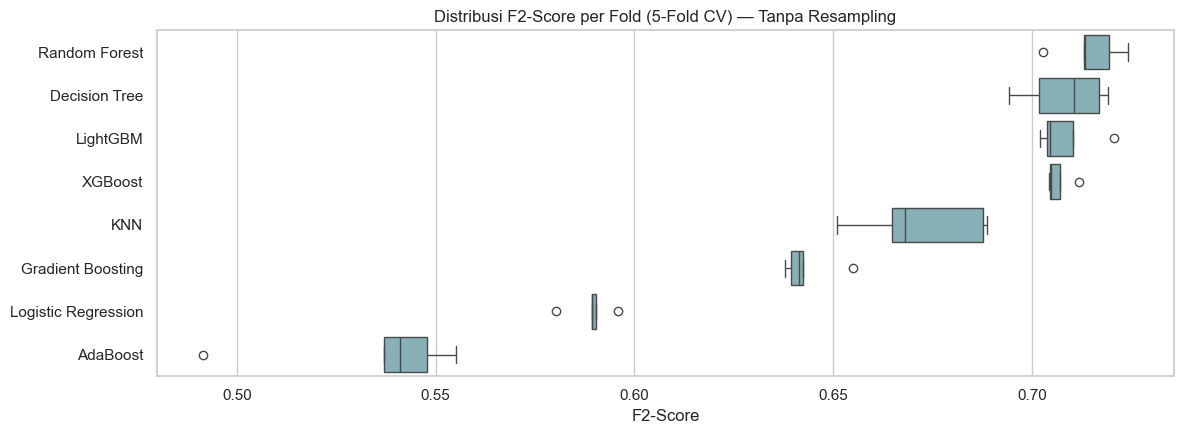

In [52]:
plt.figure(figsize=(12, 4.5))
order = benchmark_cv.index.tolist()
sns.boxplot(data=pd.DataFrame(cv_results)[order], orient='h', color='#7FB7BE')
plt.title('Distribusi F2-Score per Fold (5-Fold CV) — Tanpa Resampling', fontsize=12)
plt.xlabel('F2-Score')
plt.tight_layout()
plt.show()

Hasil benchmarking dengan *default hyperparameter* (tanpa penanganan *imbalance*):
- **Random Forest** memiliki F2-Score tertinggi (0,7145), diikuti **Decision Tree** (0,7085), **LightGBM** (0,7082), dan **XGBoost** (0,7065). Selisih keempat model ini sangat tipis (< 0,01).
- Dari sisi **ROC-AUC**, model *boosting* **XGBoost (0,8942)** dan **LightGBM (0,8935)** adalah yang terbaik. Artinya kedua model ini paling baik dalam **mengurutkan** booking dari yang paling berisiko sampai yang paling aman. F2 mereka sedikit lebih rendah hanya karena *threshold* 0,5 belum optimal.
- **Logistic Regression** dan **AdaBoost** memiliki precision tinggi tetapi **recall sangat rendah** (0,55 dan 0,49). Banyak booking batal yang tidak tertangkap, sehingga F2-nya rendah. Pola pembatalan pada data ini bersifat **non-linear dan penuh interaksi antar fitur** (contoh: `Non Refund` + `Groups` + `PRT`), yang lebih cocok ditangkap model berbasis *tree*.
- Standar deviasi F2 semua model kecil (≤ 0,023), sehingga hasilnya **stabil** antar fold.
- Secara umum, **recall seluruh model masih di bawah 0,71**, artinya ±30% booking batal belum tertangkap. Ini wajar karena kelas cancel adalah minoritas. Pada tahap berikutnya kita akan menangani *imbalance* untuk meningkatkan recall.

### 6.3 Model Benchmarking : Test Data

Sebagai pengecekan konsistensi, kita juga melihat performa setiap model (*default*) pada data test. **Catatan:** pemilihan model tetap berdasarkan hasil *cross validation* di atas; hasil test di sini hanya untuk memastikan performa di data yang belum pernah dilihat konsisten dengan hasil CV (tidak *overfitting*).

In [53]:
listTest = []
for name, model in models.items():
    estimator = Pipeline([('preprocess', transformer), ('model', model)])
    estimator.fit(X_train, y_train)
    y_pred = estimator.predict(X_test)
    y_proba = estimator.predict_proba(X_test)[:, 1]
    listTest.append([name, fbeta_score(y_test, y_pred, beta=2), recall_score(y_test, y_pred),
                     precision_score(y_test, y_pred), roc_auc_score(y_test, y_proba)])

benchmark_test = pd.DataFrame(listTest, columns=['model', 'F2 test', 'recall test', 'precision test', 'ROC-AUC test'])
benchmark_test = benchmark_test.set_index('model').sort_values('F2 test', ascending=False)
benchmark_test.round(4)

,F2 test,recall test,precision test,ROC-AUC test
model,,,,
Random Forest,0.7200,0.7104,0.7611,0.8904
Decision Tree,0.7145,0.7039,0.7604,0.8811
XGBoost,0.7048,0.6883,0.7797,0.8946
LightGBM,0.7025,0.6862,0.7766,0.8937
KNN,0.6637,0.6452,0.7493,0.8489
Gradient Boosting,0.6403,0.6088,0.8071,0.8817
Logistic Regression,0.5863,0.5512,0.7865,0.8545
AdaBoost,0.5362,0.4911,0.8484,0.8522


Hasil pada data test **konsisten** dengan hasil *cross validation*: urutan 4 model teratas tetap Random Forest, Decision Tree, XGBoost, dan LightGBM dengan F2 ±0,70–0,72, dan nilainya sangat dekat dengan rata-rata CV. Artinya model **tidak overfitting** dan hasil CV dapat dipercaya sebagai dasar pemilihan model.

Mari kita lanjutkan dengan **4 model terbaik** (Random Forest, Decision Tree, LightGBM, XGBoost) ke tahap penanganan *imbalanced data*.

### 6.4 Handling Imbalanced Data

Proporsi kelas 63:37 membuat model cenderung lebih "berhati-hati" menebak kelas cancel (recall rendah). Karena metric kita (F2) menekankan recall, kita uji beberapa metode penanganan *imbalance* pada **4 model terbaik** hasil benchmarking:

| Metode | Cara kerja |
| --- | --- |
| **RandomOverSampler (ROS)** | Menduplikasi data kelas minoritas (cancel) secara acak sampai jumlahnya sama dengan kelas mayoritas |
| **RandomUnderSampler (RUS)** | Mengurangi data kelas mayoritas (tidak cancel) secara acak sampai jumlahnya sama dengan kelas minoritas |
| **SMOTE** | Membuat data sintetis kelas minoritas dengan interpolasi antara data minoritas dan tetangga terdekatnya |
| **NearMiss** | *Undersampling* dengan memilih data mayoritas yang paling dekat dengan data minoritas |
| **Class Weight** | Tidak mengubah data, tetapi memberi bobot *error* lebih besar pada kelas minoritas di fungsi *loss* model |

Resampling diletakkan **di dalam Pipeline** (`imblearn.pipeline`) sehingga hanya diterapkan pada fold train di setiap iterasi CV. Data validation tetap memiliki distribusi asli, sehingga evaluasinya adil dan tidak terjadi *data leakage*.

In [54]:
top4 = benchmark_cv.index[:4].tolist()
print('4 model terbaik :', top4)

def get_model(name, balanced=False):
    # Membuat model baru (fresh) dengan opsi class weight
    spw = (y_train == 0).sum() / (y_train == 1).sum()
    if name == 'Random Forest':
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced' if balanced else None)
    if name == 'Decision Tree':
        return DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced' if balanced else None)
    if name == 'XGBoost':
        return XGBClassifier(random_state=RANDOM_STATE, verbosity=0, n_jobs=-1, scale_pos_weight=spw if balanced else 1)
    if name == 'LightGBM':
        return LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1, class_weight='balanced' if balanced else None)
    if name == 'Gradient Boosting':
        return GradientBoostingClassifier(random_state=RANDOM_STATE)
    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced' if balanced else None)
    return models[name]

resamplers = {'None': None,
              'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
              'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
              'SMOTE': SMOTE(random_state=RANDOM_STATE),
              'NearMiss': NearMiss(),
              'Class Weight': 'balanced'}

listResampling = []
for name in top4:
    for rs_name, rs in resamplers.items():
        steps = [('preprocess', transformer)]
        if rs is not None and rs != 'balanced':
            steps.append(('resampling', rs))
        steps.append(('model', get_model(name, balanced=(rs == 'balanced'))))
        cv = cross_validate(Pipeline(steps), X_train, y_train, cv=skfold, scoring=scoring)
        listResampling.append([name, rs_name, cv['test_f2'].mean(), cv['test_f2'].std(), cv['test_recall'].mean(),
                               cv['test_precision'].mean(), cv['test_roc_auc'].mean()])

resampling_result = pd.DataFrame(listResampling, columns=['model', 'resampling', 'mean F2', 'std F2', 'mean recall', 'mean precision', 'mean ROC-AUC'])
resampling_result.sort_values('mean F2', ascending=False).reset_index(drop=True).round(4)

4 model terbaik : ['Random Forest', 'Decision Tree', 'LightGBM', 'XGBoost']


,model,resampling,mean F2,std F2,mean recall,mean precision,mean ROC-AUC
0,Random Forest,RandomUnderSampler,0.7808,0.0047,0.8119,0.6768,0.8879
1,Decision Tree,Class Weight,0.7765,0.0042,0.8053,0.6795,0.8784
2,Random Forest,RandomOverSampler,0.7756,0.0056,0.8018,0.6859,0.8879
3,Random Forest,Class Weight,0.7755,0.0054,0.8011,0.6879,0.8889
4,Decision Tree,RandomUnderSampler,0.7754,0.0055,0.8040,0.6788,0.8742
5,Decision Tree,RandomOverSampler,0.7739,0.0047,0.7997,0.6855,0.8779
6,Random Forest,SMOTE,0.7729,0.0052,0.7966,0.6908,0.8887
7,XGBoost,Class Weight,0.7728,0.0054,0.7936,0.6997,0.8940
8,XGBoost,RandomUnderSampler,0.7725,0.0042,0.7938,0.6977,0.8934
9,XGBoost,RandomOverSampler,0.7722,0.0044,0.7927,0.6998,0.8938


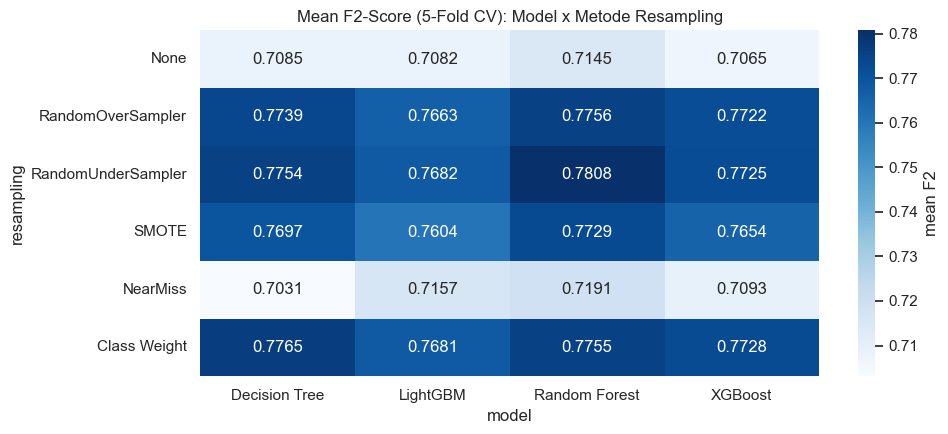

In [55]:
pivot_rs = resampling_result.pivot(index='resampling', columns='model', values='mean F2')
plt.figure(figsize=(10, 4.5))
sns.heatmap(pivot_rs.loc[list(resamplers.keys())], annot=True, fmt='.4f', cmap='Blues', cbar_kws={'label': 'mean F2'})
plt.title('Mean F2-Score (5-Fold CV): Model x Metode Resampling', fontsize=12)
plt.tight_layout()
plt.show()

Hasil penanganan *imbalanced data*:
1. **Hampir semua metode resampling meningkatkan F2-Score secara signifikan**, dari ±0,71 (tanpa resampling) menjadi ±0,77–0,78. Peningkatan ini berasal dari **recall yang naik** (±0,69–0,70 → ±0,79–0,81), dengan konsekuensi precision turun (±0,76–0,77 → ±0,68–0,70). Ini sesuai dengan tujuan kita karena FN lebih mahal daripada FP.
2. **ROC-AUC hampir tidak berubah** dengan resampling. Resampling tidak membuat model lebih "pintar" mengurutkan risiko, tetapi **menggeser batas keputusan** sehingga model lebih berani menebak kelas cancel.
3. **NearMiss memberikan hasil terburuk** (F2 ±0,70–0,72) dan bahkan menurunkan ROC-AUC. NearMiss hanya menyisakan data mayoritas yang paling mirip dengan data minoritas, sehingga distribusi data latih menjadi tidak representatif.
4. **RandomOverSampler, RandomUnderSampler, dan Class Weight menghasilkan skor yang hampir sama** (selisih hanya ±0,005, setara dengan standar deviasinya). SMOTE sedikit di bawahnya karena SMOTE membuat data sintetis dengan interpolasi, padahal sebagian besar fitur kita adalah hasil encoding kategorikal (nilai 0/1) sehingga data sintetisnya kurang realistis.

Metode resampling terbaik untuk setiap model:
- **Random Forest + RandomUnderSampler** → F2 0,7808
- **Decision Tree + Class Weight** → F2 0,7766
- **XGBoost + Class Weight** → F2 0,7728
- **LightGBM + RandomUnderSampler** → F2 0,7682

Keempat kombinasi ini akan kita *tuning* hyperparameter-nya.

### 6.5 Hyperparameter Tuning

Kita lakukan *hyperparameter tuning* pada **4 kandidat model** (masing-masing dengan metode resampling terbaiknya) menggunakan **RandomizedSearchCV** (5-Fold Stratified CV, scoring F2). RandomizedSearchCV dipilih dibanding GridSearchCV karena ruang hyperparameter cukup besar. Dengan mengambil sampel kombinasi secara acak dari distribusi yang ditentukan, kita bisa mengeksplorasi lebih banyak variasi nilai dengan waktu komputasi yang jauh lebih efisien.

References :
1. https://xgboost.readthedocs.io/en/stable/parameter.html
2. https://lightgbm.readthedocs.io/en/latest/Parameters.html
3. https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html
4. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [56]:
param_spaces = {
    'XGBoost': {
        'model__n_estimators': randint(100, 600),        # jumlah tree
        'model__max_depth': randint(3, 11),              # kedalaman maksimum tree
        'model__learning_rate': loguniform(0.01, 0.3),   # besar langkah koreksi tiap tree
        'model__subsample': uniform(0.6, 0.4),           # proporsi baris per tree (0.6 - 1.0)
        'model__colsample_bytree': uniform(0.5, 0.5),    # proporsi fitur per tree (0.5 - 1.0)
        'model__min_child_weight': randint(1, 10),       # minimal "bobot" data di sebuah leaf
        'model__gamma': uniform(0, 2),                   # minimal penurunan loss untuk melakukan split
        'model__reg_lambda': loguniform(0.1, 10)         # regularisasi L2 pada bobot leaf
    },
    'LightGBM': {
        'model__n_estimators': randint(100, 600),
        'model__num_leaves': randint(15, 128),           # jumlah maksimum leaf per tree
        'model__learning_rate': loguniform(0.01, 0.3),
        'model__subsample': uniform(0.6, 0.4),
        'model__subsample_freq': [1],
        'model__colsample_bytree': uniform(0.5, 0.5),
        'model__min_child_samples': randint(5, 60),      # minimal jumlah data di sebuah leaf
        'model__reg_lambda': loguniform(0.01, 10),
        'model__max_depth': [-1, 6, 8, 10, 12]           # -1 = tanpa batas
    },
    'Random Forest': {
        'model__n_estimators': randint(100, 500),
        'model__max_depth': [None, 10, 15, 20, 30],
        'model__min_samples_split': randint(2, 20),
        'model__min_samples_leaf': randint(1, 10),
        'model__max_features': ['sqrt', 'log2', 0.5, 0.7]
    },
    'Decision Tree': {
        'model__max_depth': [None, 5, 8, 10, 15, 20, 30],
        'model__min_samples_split': randint(2, 50),
        'model__min_samples_leaf': randint(1, 30),
        'model__criterion': ['gini', 'entropy']
    }
}
n_iter_search = {'XGBoost': 30, 'LightGBM': 30, 'Random Forest': 20, 'Decision Tree': 30}

In [57]:
# Pilih metode resampling terbaik untuk setiap model (4 kandidat), lalu lakukan tuning pada masing-masing kandidat
best_rs_per_model = resampling_result.loc[resampling_result.groupby('model')['mean F2'].idxmax()].sort_values('mean F2', ascending=False)
candidates = best_rs_per_model.reset_index(drop=True)
display(candidates.round(4))

def build_pipeline(name, rs_name):
    steps = [('preprocess', transformer)]
    rs = resamplers[rs_name]
    if rs is not None and rs != 'balanced':
        steps.append(('resampling', rs))
    steps.append(('model', get_model(name, balanced=(rs == 'balanced'))))
    return Pipeline(steps)

tuned_searches = {}
listTuning = []
for _, row in candidates.iterrows():
    name, rs_name = row['model'], row['resampling']
    search = RandomizedSearchCV(build_pipeline(name, rs_name), param_distributions=param_spaces[name], n_iter=n_iter_search[name],
                                scoring=f2_scorer, cv=skfold, random_state=RANDOM_STATE, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    tuned_searches[name] = search
    listTuning.append([name, rs_name, row['mean F2'], search.best_score_, search.best_score_ - row['mean F2']])
    print(f'{name} + {rs_name} selesai | best CV F2 = {search.best_score_:.4f}')

tuning_result = pd.DataFrame(listTuning, columns=['model', 'resampling', 'CV F2 default', 'CV F2 tuned', 'peningkatan'])
tuning_result = tuning_result.sort_values('CV F2 tuned', ascending=False).reset_index(drop=True)
tuning_result.round(4)

,model,resampling,mean F2,std F2,mean recall,mean precision,mean ROC-AUC
0,Random Forest,RandomUnderSampler,0.7808,0.0047,0.8119,0.6768,0.8879
1,Decision Tree,Class Weight,0.7765,0.0042,0.8053,0.6795,0.8784
2,XGBoost,Class Weight,0.7728,0.0054,0.7936,0.6997,0.8940
3,LightGBM,RandomUnderSampler,0.7682,0.0071,0.7869,0.7017,0.8931


Random Forest + RandomUnderSampler selesai | best CV F2 = 0.7805
Decision Tree + Class Weight selesai | best CV F2 = 0.7762
XGBoost + Class Weight selesai | best CV F2 = 0.7769
LightGBM + RandomUnderSampler selesai | best CV F2 = 0.7819


,model,resampling,CV F2 default,CV F2 tuned,peningkatan
0,LightGBM,RandomUnderSampler,0.7682,0.7819,0.0137
1,Random Forest,RandomUnderSampler,0.7808,0.7805,-0.0003
2,XGBoost,Class Weight,0.7728,0.7769,0.0041
3,Decision Tree,Class Weight,0.7765,0.7762,-0.0004


Hasil *hyperparameter tuning* (CV F2 pada data train):

| Model | Resampling | CV F2 default | CV F2 tuned | Perubahan |
| --- | --- | --- | --- | --- |
| **LightGBM** | RandomUnderSampler | 0,7682 | **0,7819** | **+0,0137** |
| Random Forest | RandomUnderSampler | 0,7808 | 0,7805 | −0,0003 |
| XGBoost | Class Weight | 0,7728 | 0,7775 | +0,0046 |
| Decision Tree | Class Weight | 0,7766 | 0,7761 | −0,0005 |

- **LightGBM mendapat peningkatan terbesar** dari tuning (+0,0137) dan menjadi model dengan **CV F2 tertinggi (0,7819)**.
- Random Forest dan Decision Tree **tidak membaik** setelah tuning. Hyperparameter *default*-nya (tree tumbuh tanpa batas kedalaman) sudah cocok dengan data yang mayoritas kategorikal dan berulang. Dalam kasus ini, kombinasi acak dari RandomizedSearchCV tidak menemukan yang lebih baik.
- **Model terpilih: LightGBM + RandomUnderSampler (tuned)**. Selain skor CV tertinggi, LightGBM juga **jauh lebih ringan dan cepat** dibanding Random Forest (tree yang dalam dan banyak), sehingga lebih praktis untuk dijalankan setiap hari pada seluruh booking yang masuk.

Catatan: selisih skor antar model teratas cukup tipis. Ini menunjukkan performa model sudah mendekati **batas informasi yang tersedia pada data** (lihat batas akurasi ±82,6% di bagian Data Cleaning), bukan karena keterbatasan algoritma.

### 6.6 Perbandingan Model Default vs Tuned (Data Test)

In [58]:
final_name = tuning_result.loc[0, 'model']
final_rs = tuning_result.loc[0, 'resampling']
final_pipeline = tuned_searches[final_name].best_estimator_
print('Model terpilih :', final_name, '+', final_rs)
print('Best hyperparameter :', tuned_searches[final_name].best_params_)

# Bandingkan semua kandidat (default vs tuned) pada data test dengan threshold 0.5
listCompare = []
for name in tuning_result['model']:
    rs_name = tuning_result.set_index('model').loc[name, 'resampling']
    for versi, est in [('Default', build_pipeline(name, rs_name).fit(X_train, y_train)), ('Tuned', tuned_searches[name].best_estimator_)]:
        pred = est.predict(X_test)
        proba = est.predict_proba(X_test)[:, 1]
        listCompare.append([f'{name} ({versi})', fbeta_score(y_test, pred, beta=2), recall_score(y_test, pred),
                            precision_score(y_test, pred), roc_auc_score(y_test, proba), average_precision_score(y_test, proba)])
        if name == final_name:
            if versi == 'Default':
                report_default = classification_report(y_test, pred)
            else:
                report_tuned = classification_report(y_test, pred)
pd.DataFrame(listCompare, columns=['model', 'F2 test', 'recall test', 'precision test', 'ROC-AUC test', 'PR-AUC test']).set_index('model').round(4)

Model terpilih : LightGBM + RandomUnderSampler
Best hyperparameter : {'model__colsample_bytree': np.float64(0.9037200775820313), 'model__learning_rate': np.float64(0.21068591627429098), 'model__max_depth': -1, 'model__min_child_samples': 5, 'model__n_estimators': 476, 'model__num_leaves': 41, 'model__reg_lambda': np.float64(0.1911275821777789), 'model__subsample': np.float64(0.9272059063689972), 'model__subsample_freq': 1}


,F2 test,recall test,precision test,ROC-AUC test,PR-AUC test
model,,,,,
LightGBM (Default),0.7608,0.7768,0.7029,0.8925,0.8505
LightGBM (Tuned),0.7738,0.7999,0.6844,0.8911,0.8483
Random Forest (Default),0.7718,0.7974,0.6837,0.8889,0.8445
Random Forest (Tuned),0.7712,0.7948,0.6891,0.8914,0.8491
XGBoost (Default),0.7726,0.7937,0.6982,0.8948,0.8536
XGBoost (Tuned),0.7710,0.7924,0.6960,0.8937,0.8526
Decision Tree (Default),0.7704,0.7948,0.6859,0.8816,0.8231
Decision Tree (Tuned),0.7726,0.7971,0.6878,0.8883,0.8462


Perbandingan pada data test (threshold 0,5):
- **LightGBM tuned memiliki F2 test tertinggi (0,7738)** di antara semua versi model, konsisten dengan hasil CV. Dibanding LightGBM *default* (0,7608), F2 naik **+0,013**, terutama karena **recall naik dari 0,777 menjadi 0,800**, sedangkan ROC-AUC praktis tetap (0,8925 → 0,8911).
- XGBoost tuned justru sedikit lebih rendah dari *default*-nya di data test, dan Random Forest relatif sama. Ini menunjukkan bahwa peningkatan kecil saat tuning tidak selalu terbawa ke data baru. Karena itu pemilihan model tetap kita dasarkan pada **CV (lebih stabil, 5 fold)**, dan hasil test di sini mengonfirmasi bahwa LightGBM tuned memang yang terbaik.

Maka **LightGBM + RandomUnderSampler (tuned)** kita gunakan sebagai model final. Selanjutnya kita optimalkan *threshold*-nya.

### 6.7 Threshold Optimization

Secara *default*, model mengklasifikasikan booking sebagai cancel jika probabilitasnya ≥ 0,5. Namun *threshold* 0,5 belum tentu optimal untuk bisnis. Kita mencari *threshold* terbaik dengan cara:
1. Membuat **prediksi *out-of-fold*** (OOF) pada data train menggunakan `cross_val_predict` (setiap data diprediksi oleh model yang tidak melatihnya), sehingga **data test tetap tidak tersentuh**.
2. Menghitung **F2-Score** dan **Total Cancellation Cost** untuk *threshold* 0,05 – 0,95.
3. Memilih *threshold* berdasarkan tujuan bisnis.

Asumsi biaya (lihat bagian 1.6):
- Biaya **FN** = ADR × rata-rata lama menginap = €101,83 × 3,43 ≈ **€349,28** (pendapatan hilang karena kamar kosong).
- Biaya **FP** = 2 × ADR = **€203,66** (*cost of walk*: tamu dipindahkan ke hotel lain).

In [59]:
ADR = 101.83          # Average Daily Rate rata-rata (EUR) - Antonio dkk. (2019)
AVG_LOS = 3.43        # rata-rata lama menginap (malam) - Antonio dkk. (2019)
COST_FN = ADR * AVG_LOS   # kamar kosong karena pembatalan tidak terantisipasi
COST_FP = 2 * ADR         # cost of walk (rule of thumb eCornell: 2x biaya kamar kosong)
print(f'Biaya per FN : EUR {COST_FN:,.2f}')
print(f'Biaya per FP : EUR {COST_FP:,.2f}')

def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn * COST_FN + fp * COST_FP

Biaya per FN : EUR 349.28
Biaya per FP : EUR 203.66


In [60]:
# Prediksi out-of-fold pada data train dengan model final (tuned)
oof_proba = cross_val_predict(final_pipeline, X_train, y_train, cv=skfold, method='predict_proba')[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
listThreshold = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    listThreshold.append([t, fbeta_score(y_train, pred, beta=2), recall_score(y_train, pred),
                          precision_score(y_train, pred), total_cost(y_train, pred)])
threshold_df = pd.DataFrame(listThreshold, columns=['threshold', 'F2', 'recall', 'precision', 'total_cost'])

best_f2_threshold = threshold_df.loc[threshold_df['F2'].idxmax(), 'threshold']
best_cost_threshold = threshold_df.loc[threshold_df['total_cost'].idxmin(), 'threshold']
print('Threshold dengan F2 maksimum           :', best_f2_threshold)
print('Threshold dengan Total Cost minimum    :', best_cost_threshold)
threshold_df[threshold_df['threshold'].isin([best_f2_threshold, 0.3, 0.4, 0.5, best_cost_threshold, 0.6, 0.7])].round(4)

Threshold dengan F2 maksimum           : 0.21
Threshold dengan Total Cost minimum    : 0.51


,threshold,F2,recall,precision,total_cost
16,0.21,0.8276,0.9603,0.5330,4.560671e+06
25,0.30,0.8251,0.9290,0.5702,4.122391e+06
35,0.40,0.8082,0.8708,0.6277,3.701052e+06
45,0.50,0.7819,0.8127,0.6790,3.536732e+06
46,0.51,0.7793,0.8072,0.6844,3.524008e+06
55,0.60,0.7307,0.7282,0.7405,3.616811e+06
65,0.70,0.6237,0.5883,0.8211,4.183225e+06


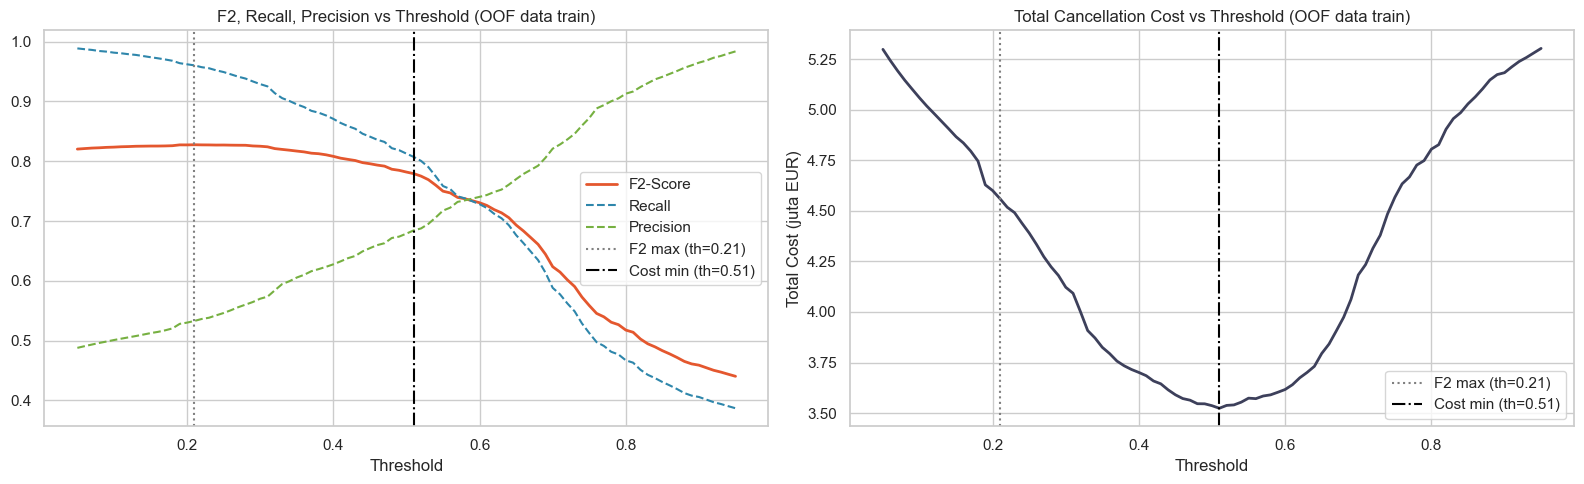

In [61]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(threshold_df['threshold'], threshold_df['F2'], label='F2-Score', color='#E4572E', linewidth=2)
ax[0].plot(threshold_df['threshold'], threshold_df['recall'], label='Recall', color='#2E86AB', linestyle='--')
ax[0].plot(threshold_df['threshold'], threshold_df['precision'], label='Precision', color='#76B041', linestyle='--')
ax[0].axvline(best_f2_threshold, color='grey', linestyle=':', label=f'F2 max (th={best_f2_threshold})')
ax[0].axvline(best_cost_threshold, color='black', linestyle='-.', label=f'Cost min (th={best_cost_threshold})')
ax[0].set_title('F2, Recall, Precision vs Threshold (OOF data train)', fontsize=12)
ax[0].set_xlabel('Threshold')
ax[0].legend()

ax[1].plot(threshold_df['threshold'], threshold_df['total_cost'] / 1e6, color='#3D405B', linewidth=2)
ax[1].axvline(best_f2_threshold, color='grey', linestyle=':', label=f'F2 max (th={best_f2_threshold})')
ax[1].axvline(best_cost_threshold, color='black', linestyle='-.', label=f'Cost min (th={best_cost_threshold})')
ax[1].set_title('Total Cancellation Cost vs Threshold (OOF data train)', fontsize=12)
ax[1].set_xlabel('Threshold')
ax[1].set_ylabel('Total Cost (juta EUR)')
ax[1].legend()
plt.tight_layout()
plt.show()

Hasil optimasi *threshold* (prediksi *out-of-fold* data train):

| Threshold | F2 | Recall | Precision | Total Cost (OOF) |
| --- | --- | --- | --- | --- |
| **0,21 (F2 maksimum)** | **0,8276** | 0,9603 | 0,5330 | €4,56 juta |
| 0,50 (default) | 0,7819 | 0,8127 | 0,6790 | €3,54 juta |
| **0,51 (cost minimum)** | 0,7793 | 0,8072 | 0,6844 | **€3,52 juta** |

**Mengapa threshold dengan F2 maksimum (0,21) TIDAK dipilih?**
- Pada threshold 0,21, recall memang sangat tinggi (96%), tetapi precision turun drastis menjadi 53%. Artinya hampir separuh booking yang diprediksi batal ternyata datang (FP sangat banyak). Akibatnya **total biaya justru naik ±€1 juta (+29%)** dibanding threshold 0,51.
- Hal ini terjadi karena F2 (β = 2) memberi bobot recall yang **lebih ekstrem** daripada rasio biaya sebenarnya (FN ≈ 1,7 × FP), dan F-score tidak memperhitungkan True Negative. F2 tetap tepat sebagai metric untuk **membandingkan model** (memastikan model kuat menangkap pembatalan), tetapi **keputusan threshold adalah keputusan bisnis** sehingga lebih tepat diambil dengan metric biaya.

**Mengapa threshold optimal berada di sekitar 0,5?**
Secara teori, jika probabilitas model terkalibrasi, threshold yang meminimalkan biaya adalah $\frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{203,66}{203,66+349,28} \approx 0,37$. Namun model kita dilatih dengan **RandomUnderSampler** (proporsi train menjadi 50:50), sehingga probabilitasnya "terangkat". Rasio data minoritas : mayoritas sebelum undersampling adalah $r \approx 30.778/52.795 \approx 0,583$. Probabilitas asli 0,37 setara dengan probabilitas model undersampling sebesar $\frac{0,37}{0,37 + 0,63 \times 0,583} \approx 0,50$, sangat dekat dengan hasil empiris (0,51). Jadi hasil optimasi threshold ini **konsisten dengan teori biaya**.

**Keputusan:** threshold final = **0,51** (biaya minimum). Kurva biaya juga cukup landai di rentang 0,45–0,55, sehingga keputusan ini tidak sensitif terhadap perubahan kecil.

In [62]:
FINAL_THRESHOLD = best_cost_threshold
print('Threshold final :', FINAL_THRESHOLD)

Threshold final : 0.51


### 6.8 Evaluasi Model Final pada Data Test

In [63]:
y_proba_final = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_final = (y_proba_final >= FINAL_THRESHOLD).astype(int)

print(f'Classification Report Model Final (threshold = {FINAL_THRESHOLD}) :\n')
print(classification_report(y_test, y_pred_final, target_names=['Tidak Cancel (0)', 'Cancel (1)']))

Classification Report Model Final (threshold = 0.51) :

                  precision    recall  f1-score   support

Tidak Cancel (0)       0.87      0.79      0.83     10559
      Cancel (1)       0.69      0.79      0.74      6156

        accuracy                           0.79     16715
       macro avg       0.78      0.79      0.78     16715
    weighted avg       0.80      0.79      0.79     16715



In [64]:
final_metrics = pd.DataFrame({
    'F2-Score': [fbeta_score(y_test, y_pred_final, beta=2)],
    'Recall': [recall_score(y_test, y_pred_final)],
    'Precision': [precision_score(y_test, y_pred_final)],
    'F1-Score': [f1_score(y_test, y_pred_final)],
    'Accuracy': [accuracy_score(y_test, y_pred_final)],
    'ROC-AUC': [roc_auc_score(y_test, y_proba_final)],
    'PR-AUC': [average_precision_score(y_test, y_proba_final)]
}, index=['Model Final (test)']).round(4)
final_metrics

,F2-Score,Recall,Precision,F1-Score,Accuracy,ROC-AUC,PR-AUC
Model Final (test),0.7698,0.7937,0.6871,0.7366,0.7909,0.8911,0.8483


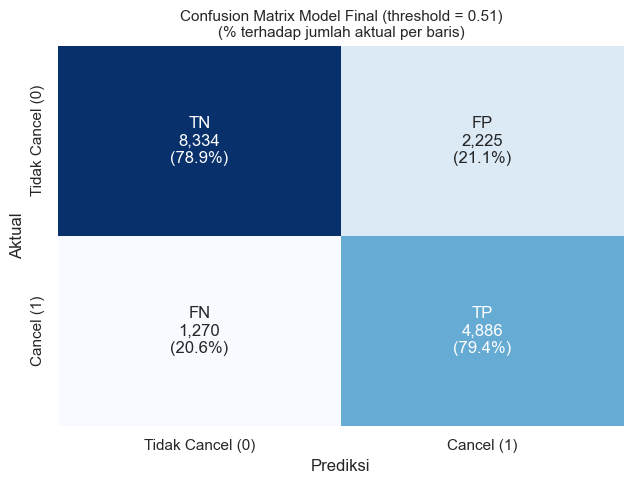

In [65]:
cm = confusion_matrix(y_test, y_pred_final)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = np.array([[f'TN\n{cm[0,0]:,}\n({cm_pct[0,0]:.1f}%)', f'FP\n{cm[0,1]:,}\n({cm_pct[0,1]:.1f}%)'],
                   [f'FN\n{cm[1,0]:,}\n({cm_pct[1,0]:.1f}%)', f'TP\n{cm[1,1]:,}\n({cm_pct[1,1]:.1f}%)']])
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, annot_kws={'fontsize': 12},
            xticklabels=['Tidak Cancel (0)', 'Cancel (1)'], yticklabels=['Tidak Cancel (0)', 'Cancel (1)'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title(f'Confusion Matrix Model Final (threshold = {FINAL_THRESHOLD})\n(% terhadap jumlah aktual per baris)', fontsize=11)
plt.tight_layout()
plt.show()

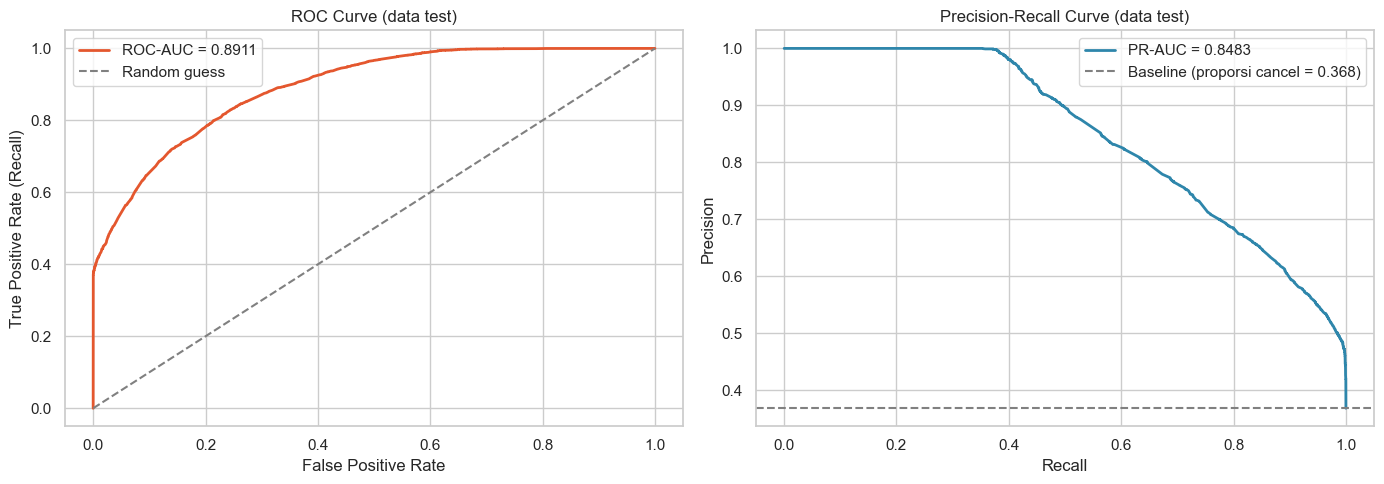

In [66]:
fpr, tpr, _ = roc_curve(y_test, y_proba_final)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_proba_final)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(fpr, tpr, color='#E4572E', linewidth=2, label=f'ROC-AUC = {roc_auc_score(y_test, y_proba_final):.4f}')
ax[0].plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random guess')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate (Recall)')
ax[0].set_title('ROC Curve (data test)', fontsize=12)
ax[0].legend()
ax[1].plot(rec_curve, prec_curve, color='#2E86AB', linewidth=2, label=f'PR-AUC = {average_precision_score(y_test, y_proba_final):.4f}')
ax[1].axhline(y_test.mean(), color='grey', linestyle='--', label=f'Baseline (proporsi cancel = {y_test.mean():.3f})')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve (data test)', fontsize=12)
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretasi performa model final pada data test (16.715 booking):**
- **F2-Score = 0,7698** → memenuhi target goal (≥ 0,75).
- **Recall = 79,37%** → dari 6.156 booking yang benar-benar batal, model berhasil menangkap **4.886 booking**. Hanya 1.270 (20,6%) yang lolos (FN).
- **Precision = 68,71%** → dari 7.111 booking yang diprediksi batal, 68,7% benar-benar batal. Masih ada 2.225 booking (21,1% dari tamu yang datang) yang salah ditandai berisiko (FP).
- **ROC-AUC = 0,8911** → jika diambil satu booking batal dan satu booking tidak batal secara acak, ada peluang 89% model memberi skor risiko lebih tinggi pada booking yang batal.
- **PR-AUC = 0,8483**, jauh di atas *baseline* acak (0,368 = proporsi cancel).
- **Accuracy = 79,09%**, cukup dekat dengan **batas atas teoretis ±82,6%** yang bisa dicapai dengan 10 fitur yang tersedia (lihat bagian 3.2).
- F2 di data test (0,7698) sangat dekat dengan F2 *out-of-fold* di data train pada threshold yang sama (0,7793), sehingga model **tidak overfitting** dan performanya diharapkan stabil pada data baru.

## 7. Interpretasi Model & Limitasi Model

### 7.1 Cara Kerja Algoritma Final: LightGBM

**LightGBM (Light Gradient Boosting Machine)** adalah algoritma *gradient boosting decision tree* yang dikembangkan Microsoft (Ke dkk., 2017). Cara kerjanya:

**1. Boosting: membangun tree secara berurutan untuk memperbaiki kesalahan**
- Model dimulai dari tebakan awal $F_0$ (log-odds rata-rata target pada data train; setelah undersampling proporsinya 50:50 sehingga $F_0 \approx 0$).
- Pada setiap iterasi $m$, untuk setiap booking dihitung **gradien** dari *log-loss*: $g_i = p_i - y_i$ (selisih antara probabilitas prediksi saat ini dan label aktual). Gradien ini menunjukkan "seberapa salah" model untuk setiap booking.
- Sebuah *decision tree* baru $h_m$ dilatih untuk memprediksi gradien negatif tersebut, yaitu mempelajari pola **kesalahan** model sebelumnya.
- Model diperbarui: $F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$, dengan $\eta$ = *learning rate*.
- Setelah $M$ tree, probabilitas pembatalan dihitung dengan fungsi sigmoid: $p(\text{cancel}) = \frac{1}{1 + e^{-F_M(x)}}$, lalu dibandingkan dengan threshold 0,51.

**2. Histogram-based splitting**: nilai fitur dikelompokkan ke dalam *bin* (histogram), sehingga pencarian titik *split* terbaik jauh lebih cepat dibanding mencoba setiap nilai unik.

**3. Leaf-wise tree growth**: berbeda dengan algoritma lain yang menumbuhkan tree per level (*level-wise*), LightGBM selalu memecah **leaf yang memberikan penurunan loss terbesar**. Hasilnya lebih akurat dengan jumlah *split* yang lebih sedikit, tetapi berisiko *overfitting* sehingga dikendalikan dengan `num_leaves`, `max_depth`, dan `min_child_samples`.

**4. Exclusive Feature Bundling (EFB) & GOSS**: EFB menggabungkan fitur-fitur *sparse* yang tidak pernah bernilai non-nol bersamaan (seperti kolom hasil One Hot Encoding) agar komputasi lebih efisien. GOSS (*Gradient-based One-Side Sampling*) memprioritaskan data dengan gradien besar (yang masih salah diprediksi).

**Alur prediksi pada pipeline final:**
`data booking mentah` → `ColumnTransformer` (One Hot, Binary Encoding, RobustScaler) → `LightGBM` → `probabilitas cancel` → `≥ 0,51 → Cancel (berisiko)`.
*RandomUnderSampler* hanya aktif saat training. Saat prediksi data baru, langkah ini dilewati otomatis oleh `imblearn.Pipeline`.

In [67]:
final_model = final_pipeline.named_steps['model']
feature_names = final_pipeline.named_steps['preprocess'].get_feature_names_out()
X_test_transformed = pd.DataFrame(final_pipeline.named_steps['preprocess'].transform(X_test), columns=feature_names)
print('Model final  :', type(final_model).__name__)
print('Resampling   :', final_pipeline.named_steps['resampling'] if 'resampling' in final_pipeline.named_steps else 'Tidak ada')
print('Threshold    :', FINAL_THRESHOLD)
print('Hyperparameter final yang di-tuning :')
for k, v in tuned_searches[final_name].best_params_.items():
    print(f'   {k.replace("model__", "")} = {round(v, 4) if isinstance(v, float) else v}')

Model final  : LGBMClassifier
Resampling   : RandomUnderSampler(random_state=42)
Threshold    : 0.51
Hyperparameter final yang di-tuning :
   colsample_bytree = 0.9037
   learning_rate = 0.2107
   max_depth = -1
   min_child_samples = 5
   n_estimators = 476
   num_leaves = 41
   reg_lambda = 0.1911
   subsample = 0.9272
   subsample_freq = 1


**Penjelasan hyperparameter final LightGBM (default → tuned):**

| Hyperparameter | Default | Tuned | Fungsi | Interpretasi |
| --- | --- | --- | --- | --- |
| `n_estimators` | 100 | **476** | Jumlah tree (iterasi boosting) | Lebih banyak tree untuk memperbaiki error secara bertahap |
| `learning_rate` | 0,1 | **0,2107** | Besar kontribusi setiap tree baru | Langkah koreksi lebih besar, diimbangi regularisasi di bawah |
| `num_leaves` | 31 | **41** | Jumlah maksimum leaf per tree | Tree sedikit lebih kompleks untuk menangkap interaksi antar fitur |
| `max_depth` | −1 | **−1** | Kedalaman maksimum tree (−1 = tanpa batas) | Kompleksitas dikendalikan oleh `num_leaves` |
| `min_child_samples` | 20 | **5** | Minimal jumlah data di sebuah leaf | Leaf kecil diperbolehkan, cocok karena banyak kombinasi fitur langka yang tetap informatif |
| `subsample` (+ `subsample_freq`=1) | 1,0 | **0,9272** | Proporsi data yang diambil acak untuk setiap tree | Menambah keacakan → mengurangi overfitting |
| `colsample_bytree` | 1,0 | **0,9037** | Proporsi fitur yang dipakai setiap tree | Menambah keacakan → mengurangi overfitting |
| `reg_lambda` | 0 | **0,1911** | Regularisasi L2 pada nilai leaf | Menahan nilai leaf agar tidak ekstrem |

Model tuned lebih kompleks (tree lebih banyak dan *learning rate* lebih besar), tetapi diimbangi oleh `subsample`, `colsample_bytree`, dan `reg_lambda`. *Learning curve* di bagian 7.7 menunjukkan bahwa model tidak mengalami *overfitting* yang serius.

### 7.2 Feature Importance

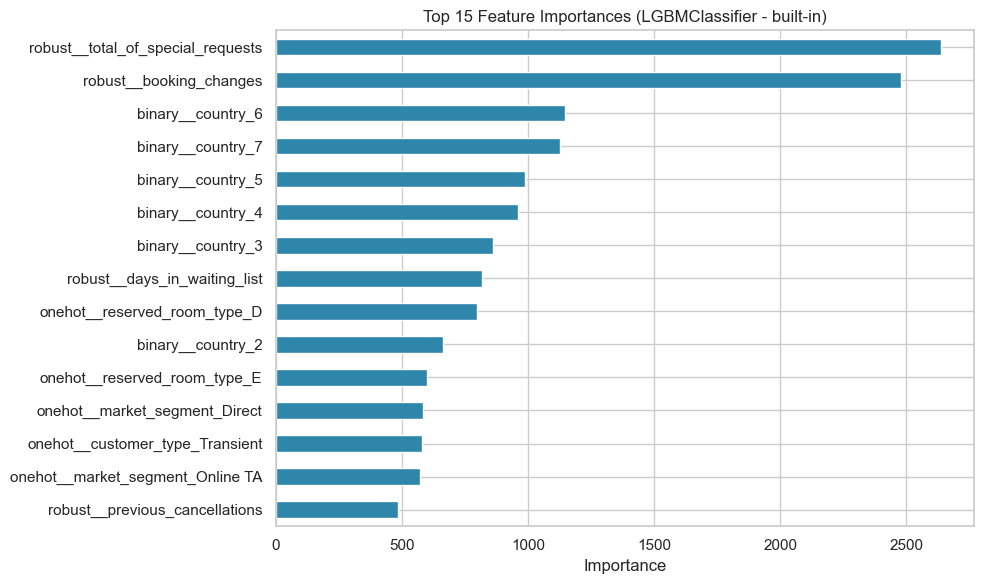

In [68]:
importance = pd.Series(final_model.feature_importances_, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importance.head(15).sort_values().plot(kind='barh', color='#2E86AB')
plt.title(f'Top 15 Feature Importances ({type(final_model).__name__} - built-in)', fontsize=12)
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

*Feature importance* bawaan model menunjukkan seberapa sering/besar sebuah fitur dipakai untuk melakukan *split* pada *tree*. Namun metode ini memiliki kelemahan: tidak menunjukkan **arah** pengaruh (menaikkan atau menurunkan risiko cancel) dan cenderung bias terhadap fitur numerik/berkardinalitas tinggi. Selain itu, fitur `country` terpecah menjadi beberapa kolom hasil Binary Encoding sehingga sulit dibaca. Oleh karena itu kita gunakan **SHAP** untuk interpretasi yang lebih akurat.

### 7.3 Interpretasi dengan SHAP (SHapley Additive exPlanations)

SHAP menjelaskan kontribusi setiap fitur terhadap prediksi **setiap booking** berdasarkan konsep *Shapley value* dari *game theory*:
- Prediksi model (dalam skala *log-odds*) = nilai dasar (rata-rata prediksi) + jumlah SHAP value seluruh fitur.
- SHAP value **positif** → fitur tersebut **menaikkan** risiko cancel; SHAP value **negatif** → **menurunkan** risiko cancel.
- Karena SHAP bersifat aditif, SHAP value dari kolom-kolom hasil *encoding* (misalnya `binary__country_0` s.d. `binary__country_7`) dapat **dijumlahkan** untuk mendapatkan kontribusi fitur aslinya (`country`).

Reference : https://shap.readthedocs.io/en/latest/

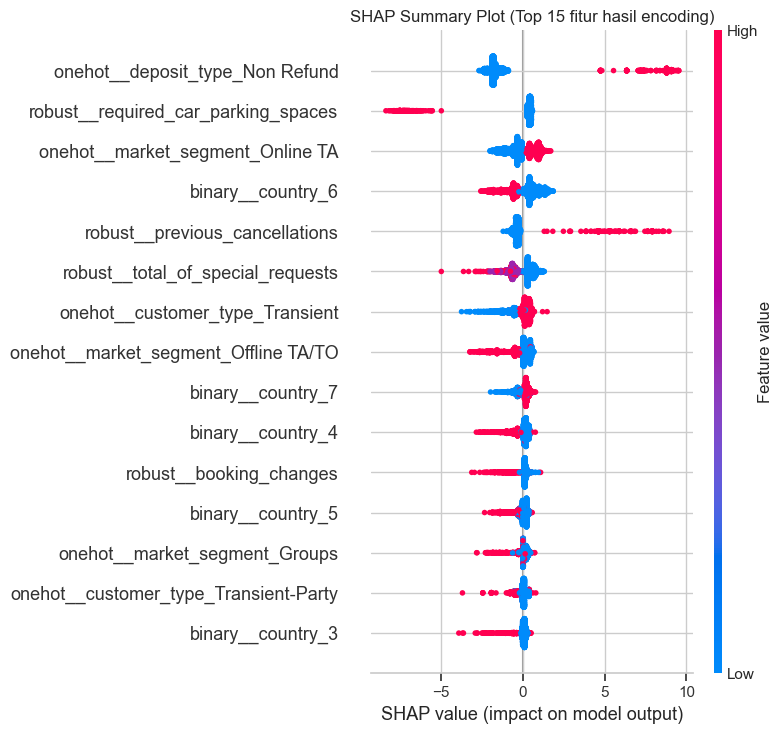

In [69]:
X_shap = X_test_transformed.sample(3000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_shap)
if len(shap_values.values.shape) == 3:      # beberapa model (misal Random Forest) mengeluarkan SHAP untuk 2 kelas
    shap_values = shap_values[:, :, 1]
shap.summary_plot(shap_values.values, X_shap, max_display=15, show=False)
plt.title('SHAP Summary Plot (Top 15 fitur hasil encoding)', fontsize=12)
plt.tight_layout()
plt.show()

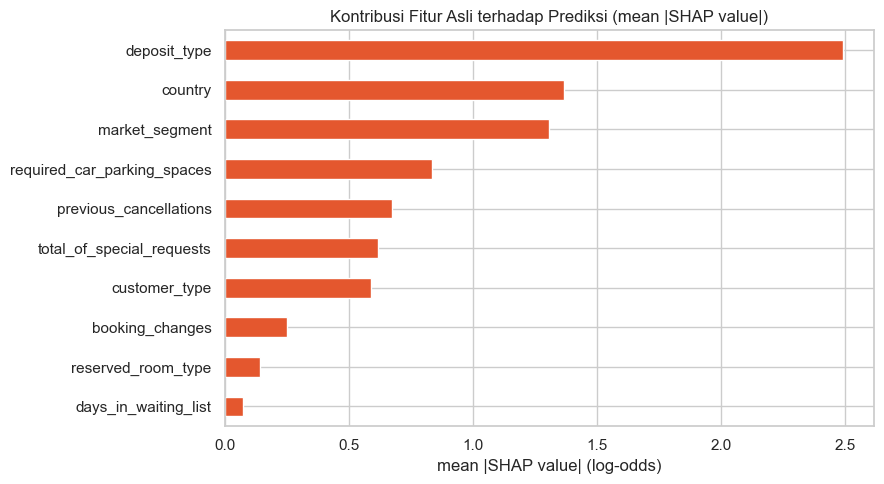

,kontribusi (%)
deposit_type,29.87
country,16.38
market_segment,15.68
required_car_parking_spaces,10.00
previous_cancellations,8.05
total_of_special_requests,7.41
customer_type,7.04
booking_changes,3.00
reserved_room_type,1.70
days_in_waiting_list,0.86


In [70]:
# Menggabungkan SHAP value kolom hasil encoding ke fitur aslinya
original_features = X_train.columns.tolist()
shap_df = pd.DataFrame(shap_values.values, columns=feature_names)
shap_grouped = pd.DataFrame({feat: shap_df[[c for c in feature_names if c.split('__', 1)[1].startswith(feat)]].sum(axis=1)
                             for feat in original_features})
shap_importance = shap_grouped.abs().mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
shap_importance.sort_values().plot(kind='barh', color='#E4572E')
plt.title('Kontribusi Fitur Asli terhadap Prediksi (mean |SHAP value|)', fontsize=12)
plt.xlabel('mean |SHAP value| (log-odds)')
plt.tight_layout()
plt.show()
(shap_importance / shap_importance.sum() * 100).round(2).rename('kontribusi (%)').to_frame()

**Interpretasi SHAP:**

Kontribusi setiap fitur asli terhadap prediksi (dari yang terbesar):
1. **`deposit_type` (29,9%)**: `Non Refund` **sangat menaikkan** risiko cancel (titik merah di sisi kanan dengan SHAP value hingga +9), sesuai temuan EDA bahwa 99,4% booking `Non Refund` batal.
2. **`country` (16,4%)**: gabungan 8 kolom Binary Encoding. Tamu domestik (`PRT`) menaikkan risiko, sedangkan sebagian besar negara Eropa lain menurunkan risiko.
3. **`market_segment` (15,7%)**: `Online TA` **menaikkan** risiko, sedangkan `Offline TA/TO` dan segmen lain (`Direct`, `Corporate`) cenderung menurunkan risiko jika fitur lain dikendalikan.
4. **`required_car_parking_spaces` (10,0%)**: meminta parkir **sangat menurunkan** risiko (SHAP value hingga −8).
5. **`previous_cancellations` (8,1%)**: riwayat pembatalan **menaikkan** risiko.
6. **`total_of_special_requests` (7,4%)**: semakin banyak *special request*, **semakin rendah** risiko.
7. **`customer_type` (7,0%)**: `Transient` sedikit menaikkan risiko.
8. `booking_changes` (3,0%), `reserved_room_type` (1,7%), dan `days_in_waiting_list` (0,9%) memiliki kontribusi kecil.

Menariknya, `days_in_waiting_list` kontribusinya sangat kecil walaupun di EDA booking yang masuk *waiting list* memiliki cancellation rate 64%. Ini karena booking *waiting list* banyak beririsan dengan booking `Groups`/`Non Refund`, sehingga informasinya **sudah terwakili oleh fitur lain**. SHAP mengukur kontribusi **tambahan** setiap fitur setelah memperhitungkan fitur lainnya.

Arah pengaruh semua fitur **konsisten dengan logika bisnis dan hasil EDA**, sehingga model dapat dipercaya tidak mempelajari pola yang aneh.

#### Contoh Penjelasan Prediksi Individual (Local Explanation)

SHAP juga bisa menjelaskan **mengapa satu booking tertentu** diprediksi berisiko tinggi atau rendah. Ini berguna bagi tim Reservation untuk memahami alasan di balik skor risiko sebuah booking.

In [71]:
idx_high = X_shap.index[np.argmax(shap_values.values.sum(axis=1))]   # booking dengan risiko tertinggi di sampel
idx_low = X_shap.index[np.argmin(shap_values.values.sum(axis=1))]    # booking dengan risiko terendah di sampel
for label, idx in [('RISIKO TINGGI', idx_high), ('RISIKO RENDAH', idx_low)]:
    pos = X_shap.index.get_loc(idx)
    print(f'===== Contoh booking {label} =====')
    display(X_test.iloc[[idx]])
    print(f'Probabilitas cancel = {y_proba_final[idx]:.4f} | Aktual = {y_test.iloc[idx]}')
    shap_local = pd.DataFrame({feat: [shap_grouped.iloc[pos][feat]] for feat in original_features}).T
    shap_local.columns = ['SHAP value']
    display(shap_local.sort_values('SHAP value', key=abs, ascending=False).round(4))

===== Contoh booking RISIKO TINGGI =====


,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests
57526,PRT,Groups,1,0,Non Refund,35,Transient,A,0,0


Probabilitas cancel = 1.0000 | Aktual = 1


,SHAP value
deposit_type,7.0640
previous_cancellations,4.3838
days_in_waiting_list,1.5383
country,1.2118
market_segment,0.6746
total_of_special_requests,0.3297
required_car_parking_spaces,0.2725
booking_changes,0.2232
reserved_room_type,0.0898
customer_type,-0.0188


===== Contoh booking RISIKO RENDAH =====


,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests
44261,GBR,Offline TA/TO,0,1,No Deposit,0,Contract,D,0,2


Probabilitas cancel = 0.0000 | Aktual = 0


,SHAP value
country,-4.0346
market_segment,-3.7389
deposit_type,-2.0646
customer_type,-1.9364
total_of_special_requests,-1.6253
booking_changes,-1.5358
reserved_room_type,-1.1112
previous_cancellations,-0.4701
required_car_parking_spaces,0.2935
days_in_waiting_list,0.0517


**Contoh interpretasi individual:**
- **Booking risiko tinggi** (`PRT`, `Groups`, `Non Refund`, pernah batal 1 kali, 35 hari di *waiting list*) → probabilitas cancel **≈ 1,00** (aktual: batal). Penyumbang terbesar adalah `deposit_type = Non Refund` (+7,06), `previous_cancellations` (+4,38), `days_in_waiting_list` (+1,54), dan `country = PRT` (+1,21).
- **Booking risiko rendah** (`GBR`, `Offline TA/TO`, `Contract`, kamar D, 2 *special request*, 1 *booking change*) → probabilitas cancel **≈ 0,00** (aktual: datang). Hampir semua fitur menurunkan risiko, terutama `country` (−4,03), `market_segment` (−3,74), `deposit_type = No Deposit` (−2,06), `customer_type = Contract` (−1,94), `total_of_special_requests` (−1,63), dan `booking_changes` (−1,54).

Dengan penjelasan seperti ini, tim Reservation dapat mengetahui **alasan** sebuah booking dianggap berisiko dan memilih tindakan yang sesuai (misalnya untuk booking grup `Non Refund`: konfirmasi ulang ke *tour operator*).

### 7.4 Kapan Model Dapat Dipercaya? (Analisis Probabilitas)

Kita kelompokkan booking di data test berdasarkan **probabilitas cancel** yang diberikan model, lalu kita lihat cancellation rate aktual dan akurasi prediksi di setiap kelompok.

In [72]:
prob_df = pd.DataFrame({'proba': y_proba_final, 'actual': y_test.values, 'pred': y_pred_final})
prob_df['prob_bin'] = pd.cut(prob_df['proba'], bins=np.arange(0, 1.01, 0.1), include_lowest=True)
prob_summary = prob_df.groupby('prob_bin', observed=False).agg(jumlah_booking=('actual', 'size'),
                                                               actual_cancel_rate=('actual', 'mean'),
                                                               akurasi_prediksi=('pred', lambda s: (s == prob_df.loc[s.index, 'actual']).mean()))
prob_summary['porsi_booking (%)'] = (prob_summary['jumlah_booking'] / len(prob_df) * 100).round(2)
prob_summary[['actual_cancel_rate', 'akurasi_prediksi']] = (prob_summary[['actual_cancel_rate', 'akurasi_prediksi']] * 100).round(2)
prob_summary

,jumlah_booking,actual_cancel_rate,akurasi_prediksi,porsi_booking (%)
prob_bin,,,,
"(-0.001, 0.1]",4511,1.93,98.07,26.99
"(0.1, 0.2]",965,12.12,87.88,5.77
"(0.2, 0.3]",1178,19.19,80.81,7.05
"(0.3, 0.4]",1732,24.25,75.75,10.36
"(0.4, 0.5]",1134,33.69,66.31,6.78
"(0.5, 0.6]",1228,38.76,39.41,7.35
"(0.6, 0.7]",1708,51.87,51.87,10.22
"(0.7, 0.8]",1206,61.69,61.69,7.22
"(0.8, 0.9]",529,64.84,64.84,3.16


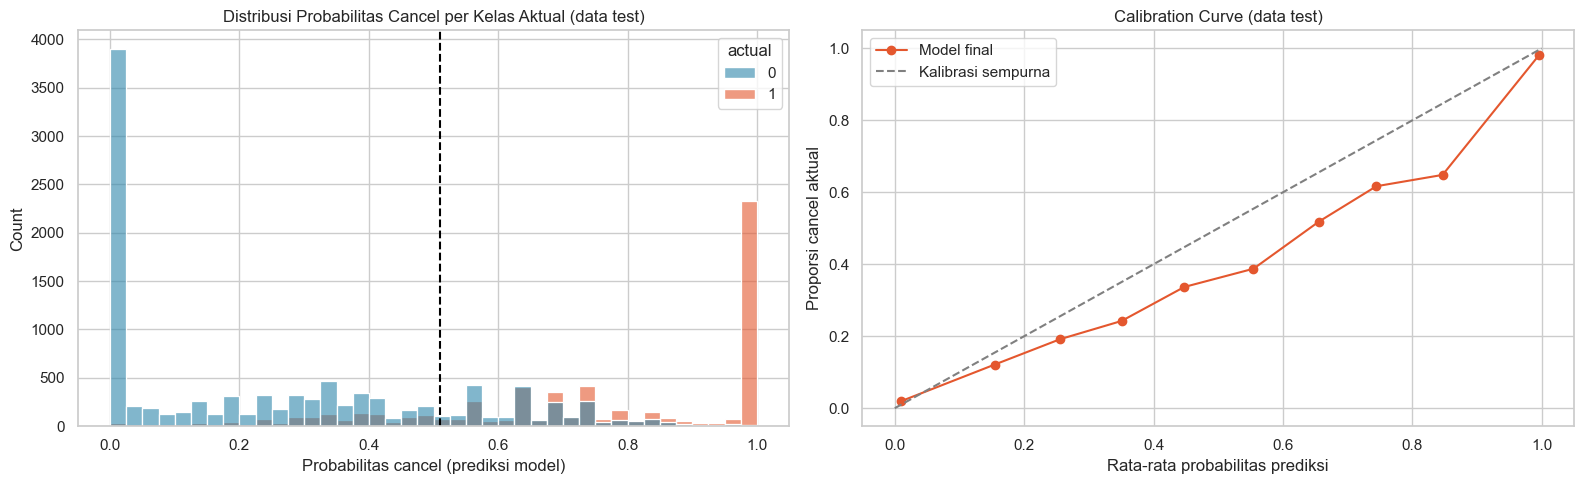

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=prob_df, x='proba', hue='actual', bins=40, ax=ax[0], palette={0: '#2E86AB', 1: '#E4572E'}, alpha=0.6)
ax[0].axvline(FINAL_THRESHOLD, color='black', linestyle='--', label=f'Threshold {FINAL_THRESHOLD}')
ax[0].set_title('Distribusi Probabilitas Cancel per Kelas Aktual (data test)', fontsize=12)
ax[0].set_xlabel('Probabilitas cancel (prediksi model)')

prob_true, prob_pred = calibration_curve(y_test, y_proba_final, n_bins=10)
ax[1].plot(prob_pred, prob_true, marker='o', color='#E4572E', label='Model final')
ax[1].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Kalibrasi sempurna')
ax[1].set_xlabel('Rata-rata probabilitas prediksi')
ax[1].set_ylabel('Proporsi cancel aktual')
ax[1].set_title('Calibration Curve (data test)', fontsize=12)
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretasi:**

| Zona risiko | Rentang probabilitas | Porsi booking | Cancellation rate aktual | Akurasi prediksi | Kesimpulan |
| --- | --- | --- | --- | --- | --- |
| **Risiko rendah** | ≤ 0,2 | 32,8% | 1,9% – 12,1% | 88% – 98% | **Sangat dapat dipercaya** |
| **Zona abu-abu** | 0,2 – 0,9 | 52,1% | 19,2% – 64,8% | 39% – 81% | **Kurang dapat dipercaya** |
| **Risiko sangat tinggi** | > 0,9 | 15,1% | 98,1% | 98% | **Sangat dapat dipercaya** |

- Model **sangat yakin dan sangat akurat** untuk booking di kedua ujung (probabilitas ≤ 0,1 atau > 0,9) yang mencakup **±42% seluruh booking**, dengan akurasi ±98%.
- Pada rentang **0,5–0,6**, akurasi hanya **39%**. Booking di rentang ini diprediksi cancel, padahal hanya 38,8% yang benar-benar batal. Ini adalah sumber utama FP.
- **Calibration curve** berada di bawah garis diagonal, artinya model **cenderung melebih-lebihkan probabilitas cancel** (*overestimate*). Ini adalah efek dari RandomUnderSampler (model dilatih dengan proporsi 50:50). Karena itu output model sebaiknya diperlakukan sebagai **skor risiko (ranking)**, bukan peluang aktual. Jika hotel ingin memakai probabilitas untuk menghitung jumlah kamar yang akan batal (*net demand*), probabilitas perlu dikalibrasi terlebih dahulu (lihat rekomendasi).

### 7.5 Performa Model per Segmen Data

Untuk mengetahui pada **data seperti apa** model akurat dan pada data seperti apa model kurang akurat, kita hitung metric per segmen pada data test.

In [74]:
eval_df = X_test.copy()
eval_df['actual'] = y_test.values
eval_df['pred'] = y_pred_final
eval_df['asal_tamu'] = np.where(eval_df['country'] == 'PRT', 'Domestik (PRT)', 'Internasional/Unknown')

def segment_performance(col):
    rows = []
    for val, g in eval_df.groupby(col):
        if len(g) < 100:
            continue
        rows.append([col, val, len(g), g['actual'].mean() * 100,
                     recall_score(g['actual'], g['pred'], zero_division=0) * 100,
                     precision_score(g['actual'], g['pred'], zero_division=0) * 100,
                     fbeta_score(g['actual'], g['pred'], beta=2, zero_division=0),
                     accuracy_score(g['actual'], g['pred']) * 100])
    return pd.DataFrame(rows, columns=['fitur', 'kategori', 'jumlah', 'cancel_rate (%)', 'recall (%)', 'precision (%)', 'F2', 'accuracy (%)'])

seg_perf = pd.concat([segment_performance(c) for c in ['deposit_type', 'market_segment', 'customer_type', 'asal_tamu']], ignore_index=True)
seg_perf.round(2)

,fitur,kategori,jumlah,cancel_rate (%),recall (%),precision (%),F2,accuracy (%)
0,deposit_type,No Deposit,14639,28.08,69.13,56.11,0.66,76.15
1,deposit_type,Non Refund,2046,99.46,99.95,99.90,1.00,99.85
2,market_segment,Complementary,113,12.39,7.14,25.00,0.08,85.84
3,market_segment,Corporate,768,17.58,45.93,77.50,0.50,88.15
4,market_segment,Direct,1825,14.25,20.00,36.88,0.22,83.73
5,market_segment,Groups,2779,61.42,97.42,92.24,0.96,93.38
6,market_segment,Offline TA/TO,3420,34.01,95.79,74.66,0.91,87.51
7,market_segment,Online TA,7774,36.89,69.46,55.52,0.66,68.20
8,customer_type,Contract,530,33.21,99.43,82.94,0.96,93.02
9,customer_type,Transient,12671,40.27,78.17,68.57,0.76,76.78


**Model akurat (dapat dipercaya) pada data:**
- `deposit_type = Non Refund` → F2 **1,00**, akurasi 99,9%.
- `market_segment = Groups` (F2 0,96) dan `Offline TA/TO` (F2 0,91).
- `customer_type = Contract` (F2 0,96).
- Tamu **domestik (PRT)** → F2 0,87, recall 90%.

**Model kurang akurat pada data:**
- `market_segment = Online TA` → F2 **0,66**, akurasi hanya 68,2%. Ini adalah **segmen terbesar** (7.774 booking di data test), sehingga menjadi sumber kesalahan terbanyak.
- `deposit_type = No Deposit` → F2 0,66.
- Tamu **internasional** → F2 0,61.
- Segmen dengan cancellation rate rendah seperti `Direct` (recall hanya 20%), `Corporate` (recall 46%), dan `Complementary` (recall 7%). Pembatalan di segmen ini jarang terjadi dan polanya tidak terlihat dari fitur yang tersedia, sehingga sebagian besar tidak tertangkap.

**Kesimpulan:** model sangat baik mengenali pembatalan berpola **"blok grup/agen"** (Non Refund, Groups, Offline TA/TO, Contract), tetapi masih kesulitan pada **booking individu tanpa deposit dari Online TA dan tamu internasional**. Keputusan batal pada booking seperti ini sangat dipengaruhi faktor yang **tidak ada di data** (misalnya *lead time*, harga, tanggal menginap, dan kebijakan *free cancellation* OTA).

### 7.6 Error Analysis: Karakteristik Booking yang Salah Diprediksi

In [75]:
eval_df['hasil'] = np.select([(eval_df['actual'] == 1) & (eval_df['pred'] == 1), (eval_df['actual'] == 0) & (eval_df['pred'] == 0),
                              (eval_df['actual'] == 0) & (eval_df['pred'] == 1), (eval_df['actual'] == 1) & (eval_df['pred'] == 0)],
                             ['TP', 'TN', 'FP', 'FN'], default='-')

profil = []
for hasil in ['TP', 'FN', 'TN', 'FP']:
    g = eval_df[eval_df['hasil'] == hasil]
    profil.append({'hasil': hasil, 'jumlah': len(g),
                   '% No Deposit': (g['deposit_type'] == 'No Deposit').mean() * 100,
                   '% Non Refund': (g['deposit_type'] == 'Non Refund').mean() * 100,
                   '% Online TA': (g['market_segment'] == 'Online TA').mean() * 100,
                   '% Groups': (g['market_segment'] == 'Groups').mean() * 100,
                   '% Domestik (PRT)': (g['country'] == 'PRT').mean() * 100,
                   '% Transient': (g['customer_type'] == 'Transient').mean() * 100,
                   '% tanpa special request': (g['total_of_special_requests'] == 0).mean() * 100,
                   '% pernah cancel': (g['previous_cancellations'] > 0).mean() * 100,
                   '% ada booking change': (g['booking_changes'] > 0).mean() * 100})
pd.DataFrame(profil).set_index('hasil').round(2)

,jumlah,% No Deposit,% Non Refund,% Online TA,% Groups,% Domestik (PRT),% Transient,% tanpa special request,% pernah cancel,% ada booking change
hasil,,,,,,,,,,
TP,4886,58.17,41.63,40.77,34.04,70.69,81.64,87.33,16.52,3.03
FN,1270,99.92,0.08,68.98,3.46,30.39,87.72,28.03,0.94,19.29
TN,8334,99.65,0.11,39.72,11.18,23.79,68.87,45.03,0.82,24.07
FP,2225,99.91,0.09,71.73,6.29,50.47,82.16,64.49,0.58,8.72


**Karakteristik kesalahan model:**
- **False Negative (booking batal yang lolos, 1.270 booking):** 99,9% `No Deposit`, 69% dari `Online TA`, hanya 30% tamu `PRT`, dan **72% memiliki special request** (hanya 28% yang tanpa request), serta 19% pernah mengubah booking. Artinya FN adalah booking yang **"terlihat seperti tamu berkomitmen"** (internasional, punya request, pernah mengubah booking) tetapi tetap batal. Model tidak memiliki informasi untuk membedakannya.
- **False Positive (tamu datang tapi ditandai berisiko, 2.225 booking):** 99,9% `No Deposit`, 72% `Online TA`, 50% tamu `PRT`, dan 64% tanpa special request. Ini adalah booking yang **"terlihat berisiko"** (domestik, OTA, tanpa request) tetapi ternyata datang.
- Kedua jenis kesalahan sama-sama terkonsentrasi pada **booking `Online TA` + `No Deposit` + `Transient`**, yaitu zona abu-abu yang sama dengan temuan pada bagian 7.4 dan 7.5. Untuk memperbaikinya dibutuhkan **fitur tambahan**, bukan sekadar algoritma lain.

### 7.7 Learning Curve

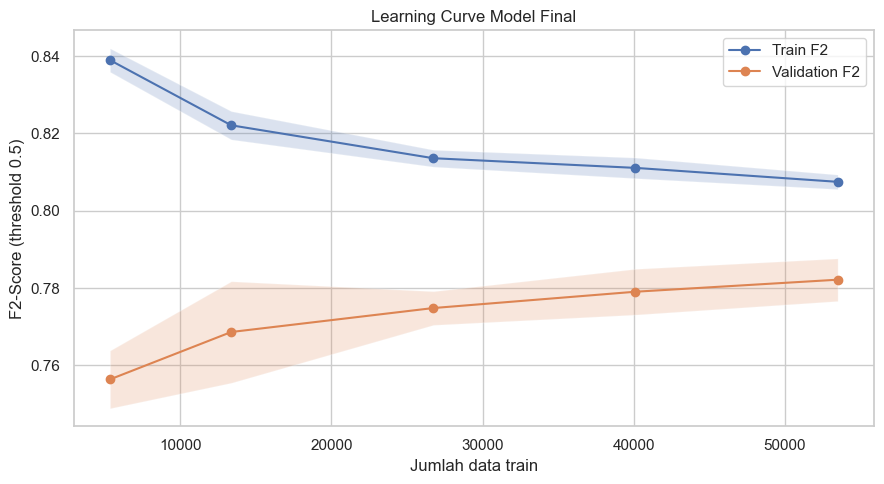

,jumlah_data_train,train_F2,validation_F2
0,5348,0.8390,0.7564
1,13371,0.8221,0.7686
2,26742,0.8136,0.7748
3,40113,0.8111,0.7790
4,53485,0.8075,0.7822


In [76]:
train_sizes, train_scores, val_scores = learning_curve(final_pipeline, X_train, y_train, cv=skfold, scoring=f2_scorer,
                                                        train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0])
plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), marker='o', label='Train F2')
plt.fill_between(train_sizes, train_scores.mean(axis=1) - train_scores.std(axis=1), train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.2)
plt.plot(train_sizes, val_scores.mean(axis=1), marker='o', label='Validation F2')
plt.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1), val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel('Jumlah data train')
plt.ylabel('F2-Score (threshold 0.5)')
plt.title('Learning Curve Model Final', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({'jumlah_data_train': train_sizes, 'train_F2': train_scores.mean(axis=1), 'validation_F2': val_scores.mean(axis=1)}).round(4)

**Interpretasi learning curve:**
- F2 validation naik dari **0,756** (5.348 data) menjadi **0,782** (53.485 data), sedangkan F2 train turun dari 0,839 menjadi 0,808. Selisih train dan validation **mengecil menjadi ±0,025**, artinya model **tidak overfitting secara serius**.
- Kenaikan F2 validation sudah **melandai** (dari 40 ribu ke 53 ribu data hanya naik ±0,003). Menambah data dengan **fitur yang sama** hanya akan memberikan peningkatan kecil. Peningkatan yang lebih berarti kemungkinan besar datang dari **penambahan fitur baru** yang lebih informatif.

### 7.8 Uji Sensitivitas: Potensi Data Leakage

Pada tahap EDA kita menemukan 2 fitur dengan pola yang mencurigakan:
- `required_car_parking_spaces`: booking yang meminta parkir **0% batal**. Bisa jadi permintaan parkir baru dicatat saat *check-in*.
- `country`: Antonio dkk. (2019) menyebutkan kewarganegaraan pasti sering baru diketahui saat *check-in*.

Jika kedua fitur ini baru terisi lengkap setelah tamu datang, maka saat model digunakan untuk booking baru (sebelum kedatangan) informasinya belum tersedia. Akibatnya, performa di dunia nyata bisa lebih rendah dari hasil evaluasi. Mari kita uji seberapa besar ketergantungan model terhadap kedua fitur ini dengan melatih ulang model (hyperparameter sama) tanpa fitur tersebut.

In [77]:
from sklearn.base import clone

def make_transformer(use_country=True, use_parking=True):
    nums = [c for c in num_cols if (use_parking or c != 'required_car_parking_spaces')]
    steps = [('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_ohe), ('robust', RobustScaler(), nums)]
    if use_country:
        steps.insert(1, ('binary', ce.BinaryEncoder(), cat_binary))
    return ColumnTransformer(steps, remainder='drop')

listSens = []
for skenario, uc, up in [('Semua fitur (model final)', True, True), ('Tanpa required_car_parking_spaces', True, False),
                         ('Tanpa country', False, True), ('Tanpa country & parking', False, False)]:
    pipe = clone(final_pipeline).set_params(preprocess=make_transformer(uc, up))
    cv = cross_validate(pipe, X_train, y_train, cv=skfold, scoring=scoring)
    listSens.append([skenario, cv['test_f2'].mean(), cv['test_recall'].mean(), cv['test_precision'].mean(), cv['test_roc_auc'].mean()])
pd.DataFrame(listSens, columns=['skenario', 'mean F2', 'mean recall', 'mean precision', 'mean ROC-AUC']).round(4)

,skenario,mean F2,mean recall,mean precision,mean ROC-AUC
0,Semua fitur (model final),0.7819,0.8127,0.6791,0.8894
1,Tanpa required_car_parking_spaces,0.7614,0.7858,0.6776,0.8773
2,Tanpa country,0.6675,0.6483,0.7573,0.8526
3,Tanpa country & parking,0.6538,0.6319,0.7588,0.8372


**Hasil uji sensitivitas:**

| Skenario | CV F2 | Perubahan F2 | CV ROC-AUC |
| --- | --- | --- | --- |
| Semua fitur (model final) | 0,7819 | – | 0,8894 |
| Tanpa `required_car_parking_spaces` | 0,7614 | −0,0205 | 0,8773 |
| Tanpa `country` | 0,6675 | **−0,1144** | 0,8526 |
| Tanpa `country` & parkir | 0,6538 | **−0,1281** | 0,8372 |

- Model **cukup bergantung pada `country`**: tanpa fitur ini F2 turun ±0,11 (recall turun dari 0,81 menjadi 0,65).
- `required_car_parking_spaces` pengaruhnya lebih kecil (F2 turun ±0,02).
- **Implikasi:** jika ternyata data `country` dan/atau parkir baru diisi lengkap **setelah tamu check-in**, performa model di dunia nyata kemungkinan **lebih rendah** dari hasil evaluasi, yaitu sekitar F2 ±0,65–0,67. Hal ini **wajib dikonfirmasi ke tim hotel/PMS** sebelum model di-*deploy*. Jika terbukti *leakage*, model harus dilatih ulang tanpa fitur tersebut.

### 7.9 Ringkasan Limitasi Model

**Limitasi data:**
1. **Fitur terbatas (10 fitur)**. Data tidak memiliki *lead time*, tanggal kedatangan/musim, harga (ADR), lama menginap, jumlah tamu, agen/perusahaan, dan *distribution channel*, padahal faktor-faktor ini dikenal sangat berpengaruh (D-EDGE: booking dengan *lead time* > 60 hari 65% lebih mungkin batal). Akibatnya ada **batas akurasi ±82,6%** yang tidak bisa dilampaui model mana pun dengan data ini.
2. **Data periode 2015–2017 dari 2 hotel di Portugal**. Perilaku pembatalan bisa sudah berubah (misalnya setelah pandemi dan perubahan kebijakan OTA), sehingga model **tidak bisa langsung diterapkan** pada hotel lain atau periode sekarang tanpa validasi ulang.
3. **Potensi data leakage** pada `country` dan `required_car_parking_spaces` (lihat 7.8).
4. Pola `Non Refund` dengan cancellation rate 99,4% berlawanan dengan logika umum dan perlu diverifikasi ke hotel.

**Limitasi model:**
1. Model **dapat dipercaya** untuk booking dengan skor risiko ≤ 0,2 atau > 0,9, serta segmen `Non Refund`, `Groups`, `Offline TA/TO`, `Contract`, dan tamu domestik.
2. Model **kurang dapat dipercaya** untuk skor risiko 0,2–0,9 (±52% booking), terutama booking `Online TA` + `No Deposit`, tamu internasional, serta segmen `Direct`/`Corporate`/`Complementary`.
3. Probabilitas model **tidak terkalibrasi** (overestimate) karena undersampling, sehingga sebaiknya dipakai sebagai skor/ranking risiko.
4. Model hanya memprediksi pembatalan. Model **tidak** memprediksi **kapan** pembatalan terjadi, padahal waktu pembatalan menentukan apakah kamar masih sempat dijual ulang.

**Limitasi asumsi bisnis & waktu:**
1. Biaya FN/FP menggunakan rata-rata ADR dan lama menginap dari paper, bukan data aktual per booking.
2. Tuning menggunakan RandomizedSearchCV dengan jumlah iterasi terbatas (20–30 kombinasi per model) karena keterbatasan waktu komputasi.

## 8. Business Impact (Cost Analysis)

Kita bandingkan biaya akibat pembatalan pada **data test (16.715 booking)** antara:
- **Tanpa model** (kondisi saat ini): hotel tidak memprediksi pembatalan, semua booking dianggap akan datang. Setiap booking yang batal menjadi kamar kosong (semua pembatalan = FN).
- **Dengan model**: booking yang diprediksi cancel diantisipasi (kamar dijual ulang / tamu dihubungi untuk retensi). Biaya timbul dari FN (pembatalan yang tidak tertangkap) dan FP (tamu yang ternyata datang tetapi kamarnya sudah dijual ulang → *walk*).

Asumsi:
- Biaya FN = **€349,28**, biaya FP = **€203,66** (lihat bagian 1.6).
- Booking yang tertangkap dengan benar (TP) diasumsikan berhasil diantisipasi sehingga tidak menimbulkan kerugian (asumsi ini diuji pada analisis sensitivitas di bawah).

In [78]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_final).ravel()
n_cancel = (y_test == 1).sum()

cost_without = n_cancel * COST_FN
cost_with = fn * COST_FN + fp * COST_FP
saving = cost_without - cost_with

impact = pd.DataFrame({
    'Tanpa Model': [0, n_cancel, 0, n_cancel * COST_FN, 0, cost_without],
    'Dengan Model': [tp, fn, fp, fn * COST_FN, fp * COST_FP, cost_with]
}, index=['Pembatalan tertangkap (TP)', 'Pembatalan tidak tertangkap (FN)', 'Tamu datang tapi diprediksi cancel (FP)',
          'Biaya kamar kosong (FN x EUR 349,28)', 'Biaya walking guest (FP x EUR 203,66)', 'TOTAL BIAYA (EUR)'])
display(impact.style.format('{:,.0f}'))
print(f'Penghematan biaya            : EUR {saving:,.0f}')
print(f'Persentase penghematan        : {saving / cost_without * 100:.2f}%')
print(f'Penghematan per 1.000 booking : EUR {saving / len(y_test) * 1000:,.0f}')

,Tanpa Model,Dengan Model
Pembatalan tertangkap (TP),0,"4,886"
Pembatalan tidak tertangkap (FN),"6,156","1,270"
Tamu datang tapi diprediksi cancel (FP),0,"2,225"
"Biaya kamar kosong (FN x EUR 349,28)","2,150,149","443,582"
"Biaya walking guest (FP x EUR 203,66)",0,"453,144"
TOTAL BIAYA (EUR),"2,150,149","896,725"


Penghematan biaya            : EUR 1,253,423
Persentase penghematan        : 58.29%
Penghematan per 1.000 booking : EUR 74,988


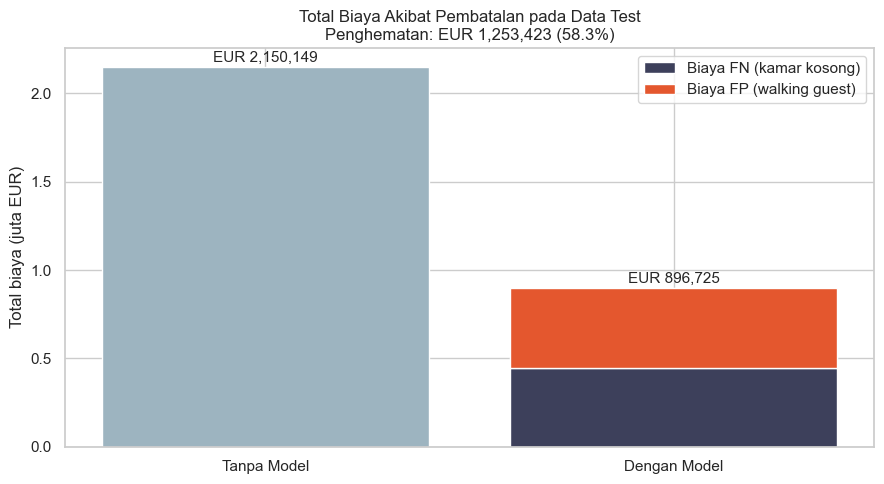

In [79]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(['Tanpa Model', 'Dengan Model'], [cost_without / 1e6, cost_with / 1e6], color=['#9DB4C0', '#E4572E'])
ax.bar(['Dengan Model'], [fn * COST_FN / 1e6], color='#3D405B', label='Biaya FN (kamar kosong)')
ax.bar(['Dengan Model'], [fp * COST_FP / 1e6], bottom=[fn * COST_FN / 1e6], color='#E4572E', label='Biaya FP (walking guest)')
for b, v in zip(bars, [cost_without, cost_with]):
    ax.text(b.get_x() + b.get_width() / 2, v / 1e6 + 0.03, f'EUR {v:,.0f}', ha='center', fontsize=11)
ax.set_ylabel('Total biaya (juta EUR)')
ax.set_title(f'Total Biaya Akibat Pembatalan pada Data Test\nPenghematan: EUR {saving:,.0f} ({saving / cost_without * 100:.1f}%)', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

#### Analisis Sensitivitas Asumsi Biaya

Asumsi biaya bisa berbeda di dunia nyata. Kita uji persentase penghematan jika:
- **Biaya FP** (*walking guest*) lebih murah atau lebih mahal (1×, 2×, 3× ADR).
- **Tingkat keberhasilan antisipasi (*recovery rate*)** pada booking yang tertangkap (TP) tidak 100%. Misalnya hanya 50% kamar yang berhasil dijual ulang atau tamunya berhasil dipertahankan, sehingga 50% sisanya tetap menjadi kerugian.

In [80]:
listSensCost = []
for fp_mult in [1, 2, 3]:
    for recovery in [1.0, 0.75, 0.5]:
        c_with = fn * COST_FN + fp * (fp_mult * ADR) + tp * (1 - recovery) * COST_FN
        listSensCost.append([f'{fp_mult}x ADR (EUR {fp_mult * ADR:,.0f})', f'{int(recovery * 100)}%', cost_without, c_with,
                             (cost_without - c_with) / cost_without * 100])
sens_cost = pd.DataFrame(listSensCost, columns=['biaya FP', 'recovery rate TP', 'biaya tanpa model', 'biaya dengan model', 'penghematan (%)'])
sens_cost.pivot(index='biaya FP', columns='recovery rate TP', values='penghematan (%)')[['100%', '75%', '50%']].round(2)

recovery rate TP,100%,75%,50%
biaya FP,,,
1x ADR (EUR 102),68.83,48.99,29.15
2x ADR (EUR 204),58.29,38.45,18.61
3x ADR (EUR 305),47.76,27.91,8.07


**Interpretasi Business Impact (data test, 16.715 booking):**

| | Tanpa Model | Dengan Model |
| --- | --- | --- |
| Pembatalan tidak terantisipasi (FN) | 6.156 → €2.150.149 | 1.270 → €443.582 |
| Tamu ter-*walk* (FP) | 0 → €0 | 2.225 → €453.144 |
| **Total biaya** | **€2.150.149** | **€896.725** |

- Dengan model, total biaya akibat pembatalan turun dari **€2,15 juta menjadi €0,90 juta**, atau **hemat €1.253.423 (58,29%)**. Ini setara dengan penghematan **±€74.988 per 1.000 booking**.
- Target goal (penghematan ≥ 30%) **tercapai**.

**Analisis sensitivitas** menunjukkan model **tetap menguntungkan pada semua skenario** (penghematan 8,1%–68,8%):
- Jika biaya *walking guest* lebih murah (1× ADR), penghematan naik menjadi 68,8%. Jika lebih mahal (3× ADR), penghematan turun menjadi 47,8%.
- Jika tidak semua pembatalan yang tertangkap berhasil diantisipasi (misalnya kamar hanya berhasil dijual ulang 75%), penghematan menjadi 38,5% (biaya FP 2× ADR).
- Dengan asumsi biaya FP 2× ADR, target penghematan ≥ 30% **tetap tercapai selama minimal ±65%** booking batal yang tertangkap berhasil diantisipasi. Karena itu, **efektivitas tindakan tim Reservation/Revenue** (seberapa cepat kamar dijual ulang atau tamu dipertahankan) sama pentingnya dengan akurasi model.

## 9. Save Model (Pickle)

Model final disimpan dalam bentuk **Pipeline lengkap** (preprocessing + resampling + model) beserta *threshold*-nya, sehingga dapat langsung digunakan untuk memprediksi data mentah booking baru tanpa perlu melakukan *encoding* manual.

In [81]:
# Fit ulang model final pada seluruh data train (sudah dilakukan oleh RandomizedSearchCV: refit=True)
model_package = {'pipeline': final_pipeline, 'threshold': FINAL_THRESHOLD, 'features': X_train.columns.tolist()}
pickle.dump(model_package, open('Model_Hotel_Booking_Cancellation.sav', 'wb'))
print('Model berhasil disimpan : Model_Hotel_Booking_Cancellation.sav')

Model berhasil disimpan : Model_Hotel_Booking_Cancellation.sav


In [82]:
# Contoh load model dan prediksi booking baru
loaded = pickle.load(open('Model_Hotel_Booking_Cancellation.sav', 'rb'))

booking_baru = pd.DataFrame([
    {'country': 'PRT', 'market_segment': 'Groups', 'previous_cancellations': 0, 'booking_changes': 0, 'deposit_type': 'Non Refund',
     'days_in_waiting_list': 0, 'customer_type': 'Transient', 'reserved_room_type': 'A', 'required_car_parking_spaces': 0, 'total_of_special_requests': 0},
    {'country': 'GBR', 'market_segment': 'Online TA', 'previous_cancellations': 0, 'booking_changes': 1, 'deposit_type': 'No Deposit',
     'days_in_waiting_list': 0, 'customer_type': 'Transient', 'reserved_room_type': 'D', 'required_car_parking_spaces': 0, 'total_of_special_requests': 2},
    {'country': 'PRT', 'market_segment': 'Online TA', 'previous_cancellations': 0, 'booking_changes': 0, 'deposit_type': 'No Deposit',
     'days_in_waiting_list': 0, 'customer_type': 'Transient', 'reserved_room_type': 'A', 'required_car_parking_spaces': 0, 'total_of_special_requests': 0}
])
proba_baru = loaded['pipeline'].predict_proba(booking_baru[loaded['features']])[:, 1]
booking_baru['probabilitas_cancel'] = proba_baru.round(4)
booking_baru['prediksi'] = np.where(proba_baru >= loaded['threshold'], 'Cancel (risiko tinggi)', 'Tidak Cancel')
booking_baru

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,probabilitas_cancel,prediksi
0,PRT,Groups,0,0,Non Refund,0,Transient,A,0,0,1.0000,Cancel (risiko tinggi)
1,GBR,Online TA,0,1,No Deposit,0,Transient,D,0,2,0.0487,Tidak Cancel
2,PRT,Online TA,0,0,No Deposit,0,Transient,A,0,0,0.6795,Cancel (risiko tinggi)


Model berhasil di-*load* kembali dan dapat memprediksi data booking baru. Hasil prediksi untuk ketiga contoh booking:
- Booking `Groups` + `Non Refund` dari `PRT` → probabilitas ≈ 1,00 → **risiko sangat tinggi** (zona yang sangat dapat dipercaya).
- Booking `Online TA` dari `GBR` dengan 1 *booking change* dan 2 *special request* → probabilitas ≈ 0,05 → **aman**.
- Booking `Online TA` dari `PRT` tanpa *special request* → probabilitas ≈ 0,68 → diprediksi cancel, tetapi berada di **zona abu-abu (0,2–0,9)**, sehingga sebaiknya ditindaklanjuti dengan *reconfirmation* dan tidak langsung dijual ulang kamarnya (lihat rekomendasi).

## 10. Conclusion & Recommendation

In [83]:
print(f'Classification Report Model Final (threshold = {FINAL_THRESHOLD}) :\n')
print(classification_report(y_test, y_pred_final, target_names=['Tidak Cancel (0)', 'Cancel (1)']))

Classification Report Model Final (threshold = 0.51) :

                  precision    recall  f1-score   support

Tidak Cancel (0)       0.87      0.79      0.83     10559
      Cancel (1)       0.69      0.79      0.74      6156

        accuracy                           0.79     16715
       macro avg       0.78      0.79      0.78     16715
    weighted avg       0.80      0.79      0.79     16715



### Conclusion

Berdasarkan seluruh proses analisis dan pemodelan, dapat disimpulkan:

1. **Model final: LightGBM + RandomUnderSampler (hyperparameter tuned) dengan threshold 0,51.** Pada data test model menghasilkan **F2-Score 0,770** (memenuhi target ≥ 0,75), **recall 79,4%**, **precision 68,7%**, **ROC-AUC 0,891**, dan **PR-AUC 0,848**.

2. **Arti hasil model untuk bisnis:** jika model digunakan untuk menyaring seluruh booking, model dapat **menangkap ±79% booking yang akan batal** (4.886 dari 6.156) sehingga hotel punya waktu untuk menjual ulang kamar atau melakukan retensi. Model juga **mengenali ±79% tamu yang benar-benar datang sebagai aman** (8.334 dari 10.559). Setiap kali model memprediksi sebuah booking akan batal, kemungkinan prediksinya benar adalah ±69%. Masih ada ±21% tamu yang datang tetapi ditandai berisiko (FP), sehingga tindakan untuk booking berisiko sedang sebaiknya bersifat "lunak" (reconfirmation) dan bukan langsung menjual ulang kamarnya.

3. **Faktor utama penyebab pembatalan** (SHAP): **`deposit_type` (Non Refund)**, **`country` (tamu domestik PRT)**, **`market_segment` (Groups & Online TA)**, dan **riwayat pembatalan** menaikkan risiko. Sebaliknya, **permintaan parkir**, **special request**, dan **perubahan booking** menurunkan risiko.

4. **Dampak bisnis:** pada data test, model menurunkan total biaya pembatalan dari **€2,15 juta menjadi €0,90 juta (hemat €1,25 juta / 58,3%)**, melampaui target 30%, dan tetap menguntungkan pada seluruh skenario sensitivitas biaya.

5. **Kapan model dapat dipercaya:** sangat akurat (±98%) untuk booking dengan skor risiko ≤ 0,1 atau > 0,9 dan untuk segmen `Non Refund`, `Groups`, `Offline TA/TO`, `Contract`, serta tamu domestik. Model kurang akurat untuk skor 0,2–0,9, terutama booking individu `Online TA` tanpa deposit dan tamu internasional.

6. Performa model sudah mendekati batas informasi data (akurasi 79,1% vs batas teoretis ±82,6%). Peningkatan berikutnya lebih bergantung pada **penambahan fitur** daripada penggantian algoritma.

### Recommendation (Bisnis)

1. **Gunakan skor risiko model dengan tindakan bertingkat (risk tiering):**
   - **Risiko sangat tinggi (skor > 0,9; ±15% booking, 98% benar-benar batal):** masukkan ke perhitungan *overbooking buffer* / siapkan kamar untuk dijual ulang, dan untuk booking grup dari *tour operator* lakukan konfirmasi ulang *rooming list* serta tetapkan *release date* lebih awal.
   - **Zona abu-abu (skor 0,2–0,9):** **jangan langsung jual ulang kamarnya**. Lakukan tindakan "lunak" seperti email/WhatsApp *reconfirmation* 3–7 hari sebelum kedatangan (D-EDGE menyarankan 3 kali pengingat: konfirmasi, pra-kedatangan, dan hari-H), tawarkan insentif kecil untuk konfirmasi (misalnya *early check-in* atau sarapan), atau minta *prepayment* parsial.
   - **Risiko rendah (skor ≤ 0,2):** proses normal, tidak perlu tindakan tambahan.

2. **Overbooking terkendali berbasis data.** Gunakan jumlah booking berisiko sangat tinggi per tanggal kedatangan sebagai dasar kuota *overbooking*, dan batasi pada rentang yang umum di industri (±2%–10%, Hospitality Net/D-EDGE) terutama saat okupansi tinggi, untuk menekan risiko *walking guest*.

3. **Evaluasi kebijakan deposit & kontrak grup.** Booking `Non Refund` 99,4% batal dan didominasi `Groups` & `Offline TA/TO` dari Portugal. Pastikan deposit benar-benar ditagih. Terapkan *cancellation penalty* atau jadwal pelepasan kamar (*allotment release*) yang jelas pada kontrak *tour operator*/agen.

4. **Kurangi ketergantungan pada channel berisiko tinggi.** `Online TA` (36,6% batal) adalah segmen terbesar, sedangkan `Direct` hanya 15,1% batal. Dorong *direct booking* (jaminan harga terbaik di website hotel, benefit member), tawarkan tarif *non-refundable* yang lebih murah, dan perpendek jendela *free cancellation* menjadi 24–48 jam sebelum kedatangan.

5. **Perhatikan pasar domestik.** Tamu `PRT` membatalkan 56% booking. Pertimbangkan *prepayment*/deposit parsial untuk booking domestik transient pada musim ramai.

6. **Tingkatkan keterlibatan tamu sebelum kedatangan.** Tamu yang memiliki *special request* atau meminta parkir jauh lebih jarang batal. Kirim email pra-kedatangan yang menanyakan preferensi kamar/parkir untuk meningkatkan keterikatan tamu. (Catatan: ini korelasi, efek kausalnya perlu diuji dengan A/B test.)

### Recommendation (Pengembangan Model & Data)

1. **Tambahkan fitur yang lebih informatif:** `lead_time`, tanggal kedatangan/musim, `adr` (harga), lama menginap, jumlah tamu, `distribution_channel`, `agent`/`company`, `is_repeated_guest`, dan tanggal booking. Penelitian Antonio dkk. (2017) dengan data yang lebih kaya mampu mencapai akurasi > 90%.
2. **Verifikasi potensi *data leakage*:** konfirmasi ke tim hotel kapan kolom `country` dan `required_car_parking_spaces` diisi. Jika baru lengkap saat *check-in*, latih ulang model tanpa fitur tersebut (perkiraan F2 ±0,65).
3. **Kalibrasi probabilitas** (misalnya `CalibratedClassifierCV` atau koreksi efek undersampling) agar output model bisa digunakan langsung untuk peramalan jumlah kamar yang batal (*net demand forecasting*).
4. **Prediksi waktu pembatalan** (misalnya *survival analysis*), karena pembatalan mendadak (H-1) jauh lebih merugikan daripada pembatalan jauh hari.
5. **Eksplorasi model lain dan tuning lebih luas:** CatBoost (menangani kategorikal secara native), Optuna/Bayesian optimization dengan iterasi lebih banyak, *stacking*, atau *cost-sensitive learning* yang langsung mengoptimalkan *Total Cancellation Cost*.
6. **Model khusus untuk segmen lemah** (`Online TA` + `No Deposit`, tamu internasional, `Direct`/`Corporate`) dengan fitur tambahan yang relevan.
7. **Monitoring & retraining berkala:** pantau recall, precision, dan biaya aktual setiap bulan. Lakukan *retraining* jika performa turun, dan uji dampak nyata model dengan *pilot*/A/B test sebelum diterapkan penuh.

## 11. Referensi

1. Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126
2. Antonio, N., de Almeida, A., & Nunes, L. (2017). *Predicting hotel booking cancellations to decrease uncertainty and increase revenue*. Tourism & Management Studies, 13(2), 25–39. https://doi.org/10.18089/tms.2017.13203
3. Hospitality Technology (2019). *Global Cancellation Rate of Hotel Reservations Reaches 40% on Average* (studi D-EDGE Hospitality Solutions). https://hospitalitytech.com/global-cancellation-rate-hotel-reservations-reaches-40-average
4. eCornell. *The Cheapest and Best Approach to Overbooking*. https://ecornell-impact.cornell.edu/the-cheapest-and-best-approach-to-overbooking/
5. AltexSoft. *Cost of Walk (COW)*. https://www.altexsoft.com/glossary/cost-of-walk-cow
6. Hospitality Net / D-EDGE. *How to prevent hotel no-show and last-minute cancellations?* https://www.hospitalitynet.org/news/4124422.html
7. Ke, G. dkk. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 30.
8. Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS 30.
9. Dokumentasi: scikit-learn, imbalanced-learn, category_encoders, LightGBM, XGBoost, SHAP.

# Thank You